In [1]:
import os, random, subprocess, re, json
import numpy as np
import pandas as pd
import nibabel as nb
import scipy.ndimage as ndim
from nilearn import image
from datetime import datetime
from nilearn.plotting import plot_roi, plot_anat, plot_epi, plot_stat_map
from intensity_normalization.typing import TissueType
from intensity_normalization.normalize.fcm import FCMNormalize

### 0. Parameters
Select which dataset to perform the analysis on:

In [2]:
dataset = "bruxelles-bids"
baseline, sd = "T1BL", "T2SD"

Select the parameters for HTCondor submission scripts:

In [3]:
# Resources
cpus = "8"
ram = "32G"
disk = "90G"

# Directories
root = "/data/project/sleep_ENIGMA_glymphatic/enigma-sd"
symlink = f"{root}/{dataset}/.git/annex/objects"
output = f"{root}/{dataset}/derivatives"
logs = f"{root}/code/logs/{dataset}"
work = "/tmp"

# Executables
conda = "/home/jd.elberse/anaconda3/bin/conda"
singularity = "/usr/bin/singularity"
bash = "/bin/bash"

# Create output and log directory
os.makedirs(output, exist_ok=True)
os.makedirs(logs, exist_ok=True)

Set working directory:

In [4]:
%cd $root

/data/project/sleep_ENIGMA_glymphatic/enigma-sd


Create a function for submitting condor jobs:

In [5]:
def submit(jobname, executable, arguments):
    submission = f"""
        universe        = vanilla
        getenv          = True 
        request_cpus    = {cpus}
        request_memory  = {ram}
        request_disk    = {disk}
        executable      = {executable}
        arguments       = {arguments}
        log             = {logs}/$(Cluster)_{jobname}_log.txt
        output          = {logs}/$(Cluster)_{jobname}_out.txt
        error           = {logs}/$(Cluster)_{jobname}_err.txt
        Queue
    """

    try:
        # Use subprocess to send the content directly to condor_submit
        result = subprocess.run(
            ["condor_submit"],
            input=submission,
            text=True,
            capture_output=True,
            check=True
        )
        print(result.stdout)  # Output from condor_submit
    except subprocess.CalledProcessError as e:
        print("Failed to submit job.")
        print(e.stderr)  # Error message from condor_submit

Create functions for getting specific subject/session derivative paths

In [6]:
# FMRIPrep

def get_fmriprep_data(sub, ses, datatype):
    fmriprep_prefix = f"{root}/{dataset}/derivatives/fmriprep/{sub}/{ses}/anat/{sub}_{ses}_space-MNI152NLin2009cAsym" # Standard version of fmriprep path
    if not os.path.exists(f"{fmriprep_prefix}_{datatype}"):
        fmriprep_prefix = f"{root}/{dataset}/derivatives/fmriprep/{sub}/{ses}/{sub}/{ses}/anat/{sub}_{ses}_space-MNI152NLin2009cAsym" # Alternative version
    return f"{fmriprep_prefix}_{datatype}" # Return

# Freesurfer

def get_freesurfer_path(sub, ses):
    freesurfer_path = f"{root}/{dataset}/derivatives/freesurfer/{ses}/{sub}" # Standard
    if not os.path.exists(freesurfer_path):
        freesurfer_path = f"{root}/{dataset}/derivatives/fmriprep/{sub}/{ses}/sourcedata/freesurfer/{sub}" # Alternative
    return freesurfer_path # Return

# QSIPrep
def get_qsiprep_data(sub, ses, datatype):
    qsiprep_prefix = f"{root}/{dataset}/derivatives/qsiprep/{sub}/{ses}/dwi/{sub}_{ses}_dir-AP_space-ACPC"
    if not os.path.exists(f"{qsiprep_prefix}_{datatype}"):
        qsiprep_prefix = f"{root}/{dataset}/derivatives/qsiprep/{sub}/{ses}/dwi/{sub}_{ses}_space-ACPC"
    return f"{qsiprep_prefix}_{datatype}"

Set up a sub list and pandas dataframe for collecting the output.

In [8]:
participants = pd.read_csv(dataset+"/participants.tsv", sep="\t") # Open the participant demographic dataset
subs = participants["participant_id"]
output_data = participants[["participant_id","site","group","age",
                            "sex","kss_score_baseline","kss_score_followup","chronotype"]] # Select columns for statistical analysis
output_data.set_index("participant_id", inplace=True) # Set participant id as index

##### Subject Exclusions

Perform subject exclusions:
* Bruxelles: these subjects had scans with Tailarach failures (poor image quality)
* SleepLess: these subjects had missing data
* Melbourne: subject-307: data corruption; subject-308: doesn't exist
* NTNU: these subjects had missing data
* Oslo: sub-59600: missing data; other subjects: eddy current/motion correction failures



In [ ]:

exclusions = {
    "bruxelles": [
        "sub-002", "sub-005", "sub-009", "sub-011", "sub-014",
        "sub-016", "sub-021", "sub-018", "sub-028", "sub-029",
    ],
    "sleepless": ["sub-008", "sub-631"],
    "melbourne-bids": ["sub-307", "sub-308"],
    "montreal": ["sub-01", "sub-29"],
    "ntnu": ["sub-6009", "sub-6017", "sub-6030", "sub-6039"],
    "oslo": [
        "sub-59600", "sub-59601", "sub-59602", "sub-59603",
        "sub-59604", "sub-59606", "sub-59607", "sub-59608",
        "sub-59612", "sub-59614", "sub-59648", "sub-59658",
    ],
}

excluded_subs = next(
    (subjects for name, subjects in exclusions.items() if name in dataset.lower()),
    [],
)

subs = subs[~subs.isin(excluded_subs)]
output_data = output_data[~output_data.index.isin(excluded_subs)]

### 1. Preprocessing
Anatomical preprocessing is run done with fmriprep. Diffusion preprocessing is done with qsiprep. Make sure the correct versions are present:

In [10]:
fmriprep = "code/containers/images/bids/bids-fmriprep--24.1.1.sing"
qsiprep = "code/containers/qsiprep-0.24.0.sif" # Custom-built container because the ReproNIM one does not have a runscript
fsl = "code/containers/images/neurodesk/neurodesk-fsl--6.0.7.14.simg" # Used later for the ALPS calculations
!datalad get $fmriprep $qsiprep $fsl

action summary:
  get (notneeded: 4)


To keep anatomical sessions separate, we need to create two bids filter files:

In [17]:
%%bash -s "$baseline" "$sd"
for ses in $1 $2;
do
    jq -n \
        --arg datatype 'anat' \
        --arg session $ses \
        --arg suffix 'T1w' \
        '{t1w: $ARGS.named}' > code/preproc/filter_${ses}.json
done

Then we can run fmriprep. Please note: depending on the size of the dataset, this step may take several hours, up to several days, to finish.

In [12]:
for ses in baseline, sd:
    fmriprep_run = (
        "run " # Singularity command
        "--cleanenv "
        f"-B {symlink},{work},{root}/{dataset},{output},/opt/freesurfer/7.4/license.txt:/opt/freesurfer/license.txt "
        f"{fmriprep} " # Singularity container
        f"{dataset} " # BIDS data directory
        f"{output}/fmriprep " # Output directory
        "participant "
        "--anat-only "
        "--skull-strip-fixed-seed "
        "--output-spaces MNI152NLin2009cAsym "
        f"--work-dir {work} "
        f"--bids-filter-file code/preproc/filter_{ses}.json "
        f"--fs-subjects-dir {output}/freesurfer/ses-{ses} "
        "--skip-bids-validation "
        "--verbose"
    )

    submit("fmriprep", singularity, fmriprep_run)

Submitting job(s).
1 job(s) submitted to cluster 11115652.

Submitting job(s).
1 job(s) submitted to cluster 11115653.



If the dataset has diffusion-weighted data, also run qsiprep. Similarly to fmriprep, this will take a long time, so check in with condor_q every now and then.

In [ ]:
qsiprep_run = (
    "run " # Singularity command
    "--cleanenv "
    f"-B {symlink},{work},{root}/{dataset},{output},/opt/freesurfer/7.4/license.txt:/opt/freesurfer/license.txt "
    f"{qsiprep} " # Singularity container
    f"{dataset} " # BIDS data directory
    f"{output}/qsiprep " # Output directory
    "participant "
    #"--dwi-only "
    f"--participant-label {' '.join(s for s in subs)} "
    f"--session-id {baseline} {sd} " 
    "--output-resolution 1 "
    f"--work-dir {work} "
    "--verbose"
)

submit("qsiprep", singularity, qsiprep_run)

Submitting job(s).
1 job(s) submitted to cluster 11143918.



##### Registering Aparc+Aseg to MNI

We use the FMRIPrep transformation matrix to take the Freesurfer derivative aparc+aseg.mgz and warp it from the Freesurfer Native to FMRIPrep T1 space.

In [ ]:
print("="*100)
for sub in subs:
    for ses in f"ses-{baseline}", f"ses-{sd}":

        print(f"Subject: {sub}")
        print(f"Session: {ses}")
        freesurfer_path = get_freesurfer_path(sub, ses)
        ref_path = get_fmriprep_data(sub, ses, 'desc-preproc_T1w.nii.gz')
        transform_path = f"{root}/{dataset}/derivatives/fmriprep/{sub}/{ses}/anat/{sub}_{ses}_from-fsnative_to-T1w_mode-image_xfm.txt"
        out_path = ref_path.replace("space-MNI152NLin2009cAsym_desc-preproc_T1w.nii.gz", "aparc+aseg.nii.gz")

        fsnative_to_t1 = (
            "antsApplyTransforms "
            "-d 3 "
            f"-i {freesurfer_path}/mri/aparc+aseg.mgz "
            f"-r {ref_path} "
            f"-t {transform_path} "
            "-n NearestNeighbor "
            f"-o {out_path} "
            "--verbose"
        )

        fmriprep_run = (
            "exec " # Singularity command
            f"-B {symlink},{work},{root}/{dataset},/opt/freesurfer/7.4/license.txt:/opt/freesurfer/license.txt "
            f"{fmriprep} " # We use the fmriprep container because it contains both Freesurfer and ANTS
            f"{fsnative_to_t1} "
        )
        if not os.path.exists(out_path):
            submit("fsnative_to_t1", singularity, fmriprep_run)
        else:
            print("File exists.")
        print("="*100)

Subject: sub-001
Session: ses-T1BL
/data/project/sleep_ENIGMA_glymphatic/enigma-sd/bruxelles-bids/derivatives/freesurfer/ses-T1BL/sub-001
File exists.
Subject: sub-001
Session: ses-buh
/data/project/sleep_ENIGMA_glymphatic/enigma-sd/bruxelles-bids/derivatives/fmriprep/sub-001/ses-buh/sourcedata/freesurfer/sub-001
Submitting job(s).
1 job(s) submitted to cluster 11164540.

Subject: sub-003
Session: ses-T1BL
/data/project/sleep_ENIGMA_glymphatic/enigma-sd/bruxelles-bids/derivatives/freesurfer/ses-T1BL/sub-003
File exists.
Subject: sub-003
Session: ses-buh
/data/project/sleep_ENIGMA_glymphatic/enigma-sd/bruxelles-bids/derivatives/fmriprep/sub-003/ses-buh/sourcedata/freesurfer/sub-003
Submitting job(s).
1 job(s) submitted to cluster 11164541.

Subject: sub-004
Session: ses-T1BL
/data/project/sleep_ENIGMA_glymphatic/enigma-sd/bruxelles-bids/derivatives/freesurfer/ses-T1BL/sub-004
File exists.
Subject: sub-004
Session: ses-buh
/data/project/sleep_ENIGMA_glymphatic/enigma-sd/bruxelles-bids/de

Then we can warp the resulting derivative from T1 to MNI space.

In [17]:
print("="*100)
for sub in subs:
    for ses in f"ses-{baseline}", f"ses-{sd}":

        print(f"Subject: {sub}")
        print(f"Session: {ses}")
        ref_path = get_fmriprep_data(sub, ses, 'desc-preproc_T1w.nii.gz')
        in_path = ref_path.replace("space-MNI152NLin2009cAsym_desc-preproc_T1w.nii.gz", "aparc+aseg.nii.gz")
        transform_path = f"{root}/{dataset}/derivatives/fmriprep/{sub}/{ses}/anat/{sub}_{ses}_from-T1w_to-MNI152NLin2009cAsym_mode-image_xfm.h5"
        out_path = ref_path.replace("desc-preproc_T1w.nii.gz", "aparc+aseg.nii.gz")
                
        t1_to_mni = (
            "antsApplyTransforms "
            "-d 3 "
            f"-i {in_path} "
            f"-r {ref_path} "
            f"-t {transform_path} "
            "-n NearestNeighbor "
            f"-o {out_path} "
            "--verbose"
        )

        fmriprep_run = (
            "exec " # Singularity command
            f"-B {symlink},{work},{root}/{dataset},/opt/freesurfer/7.4/license.txt:/opt/freesurfer/license.txt "
            f"{fmriprep} " # We use the fmriprep container because it contains both Freesurfer and ANTS
            f"{t1_to_mni} "
        )
        
        if not os.path.exists(out_path):
            submit("t1_to_mni", singularity, fmriprep_run)
        else:
            print("File exists.")
        print("="*100)

Subject: sub-001
Session: ses-T1BL
Submitting job(s).
1 job(s) submitted to cluster 11164569.

Subject: sub-001
Session: ses-buh
Submitting job(s).
1 job(s) submitted to cluster 11164570.

Subject: sub-003
Session: ses-T1BL
Submitting job(s).
1 job(s) submitted to cluster 11164571.

Subject: sub-003
Session: ses-buh
Submitting job(s).
1 job(s) submitted to cluster 11164572.

Subject: sub-004
Session: ses-T1BL
Submitting job(s).
1 job(s) submitted to cluster 11164573.

Subject: sub-004
Session: ses-buh
Submitting job(s).
1 job(s) submitted to cluster 11164574.

Subject: sub-006
Session: ses-T1BL
Submitting job(s).
1 job(s) submitted to cluster 11164575.

Subject: sub-006
Session: ses-buh
Submitting job(s).
1 job(s) submitted to cluster 11164576.

Subject: sub-007
Session: ses-T1BL
Submitting job(s).
1 job(s) submitted to cluster 11164577.

Subject: sub-007
Session: ses-buh
Submitting job(s).
1 job(s) submitted to cluster 11164578.

Subject: sub-008
Session: ses-T1BL
Submitting job(s).
1

Double check if all subjects were preprocessed successfully, and if all required files are present.

### 2. Perivascular Space Segmentation
To segment the perivascular spaces (PVS) from anatomical scans, we will use the SHIVA U-Net. First, we have to set up the derivatives folder in the correct format.

In [11]:
shiva_root = f"{root}/{dataset}/derivatives/shiva"
!mkdir -p {shiva_root} {shiva_root}/inputs {shiva_root}/outputs

Now we move selected FMRIPrep derivatives into the inputs folder:

In [25]:
print("="*100)
for sub in subs:
    for ses in f"ses-{baseline}", f"ses-{sd}":
        if ses == f"ses-{baseline}":
            continue
        # Parameters
        print(f"Subject: {sub}")
        print(f"Session: {ses}")
        t1_path = get_fmriprep_data(sub, ses, "desc-preproc_T1w.nii.gz")
        seg_path = get_fmriprep_data(sub, ses, "aparc+aseg.nii.gz")

        # "Standard" formatting
        shiva_t1_dir = f"{shiva_root}/inputs/{sub}_{ses}/t1"
        shiva_seg_dir = f"{shiva_root}/inputs/{sub}_{ses}/seg"

        # Create directories and copy
        print("Creating directories")
        !mkdir -p {shiva_t1_dir} {shiva_seg_dir} && chmod +rw -R {shiva_root}
        print("Copying T1 data")
        !cp {t1_path} {shiva_t1_dir}/{sub}_{ses}_T1.nii.gz
        print("Copying parcellations")
        !cp {seg_path} {shiva_seg_dir}/{sub}_{ses}_seg.nii.gz
        print("="*100)

Subject: sub-001
Session: ses-T2SD
Creating directories
Copying T1 data
Copying parcellations
Subject: sub-003
Session: ses-T2SD
Creating directories
Copying T1 data
Copying parcellations
Subject: sub-004
Session: ses-T2SD
Creating directories
Copying T1 data
Copying parcellations
Subject: sub-006
Session: ses-T2SD
Creating directories
Copying T1 data
Copying parcellations
Subject: sub-007
Session: ses-T2SD
Creating directories
Copying T1 data
Copying parcellations
Subject: sub-008
Session: ses-T2SD
Creating directories
Copying T1 data
Copying parcellations
Subject: sub-010
Session: ses-T2SD
Creating directories
Copying T1 data
Copying parcellations
Subject: sub-012
Session: ses-T2SD
Creating directories
Copying T1 data
Copying parcellations
Subject: sub-013
Session: ses-T2SD
Creating directories
Copying T1 data
Copying parcellations
Subject: sub-015
Session: ses-T2SD
Creating directories
Copying T1 data
Copying parcellations
Subject: sub-017
Session: ses-T2SD
Creating directories
Copy

SHIVA inference needs to be run on a CUDA-capable GPU. This means we have to edit our submit parameters a bit.

In [20]:
def shiva_submit(jobname, executable, arguments):
    submission = f"""
        universe        = vanilla
        getenv          = True
        request_GPUs    = 4
        request_memory  = {ram}
        request_disk    = {disk}
        executable      = {executable}
        arguments       = {arguments}
        log             = {logs}/$(Cluster)_{jobname}_log.txt
        output          = {logs}/$(Cluster)_{jobname}_out.txt
        error           = {logs}/$(Cluster)_{jobname}_err.txt
        Queue
    """

    try:
        # Use subprocess to send the content directly to condor_submit
        result = subprocess.run(
            ["condor_submit"],
            input=submission,
            text=True,
            capture_output=True,
            check=True
        )
        print("Job submitted successfully!")
        print(result.stdout)  # Output from condor_submit
    except subprocess.CalledProcessError as e:
        print("Failed to submit job.")
        print(e.stderr)  # Error message from condor_submit

Run the SHIVAI container:

This does not work currently. Instead, it needs to be run interactively with the following command:
`singularity exec --nv -B $(pwd) -B code/shiva/patched_image.py:/usr/local/lib/python3.8/dist-packages/shivai/interfaces/image.py code/containers/shiva_0.4.2.sif shiva --in $dataset/derivatives/shiva/inputs --out $dataset/derivatives/shiva/outputs --config code/shiva/shiva_config.yml --prediction PVS --input_type standard --brain_seg custom --custom_LUT code/shiva/FreeSurferColorLUT.txt  `


After activating the right environment:
`conda activate SHIVA_PVS`

In [26]:
# Parameters
shivai = f"{root}/code/containers/shiva_0.4.2.sif"

# Commands
shivai_infer = (
    f"run -n SHIVA_PVS "
    f"singularity exec --nv "
    f"-B {root},code/shiva/patched_image.py:/usr/local/lib/python3.8/dist-packages/shivai/interfaces/image.py " 
    f"{shivai} "
    #f"{conda} run -n SHIVA_PVS "
    #"python code/shiva/run_shiva.py " # Shiva inference script
    f"shiva "
    f"--in {shiva_root}/inputs "
    f"--out {shiva_root}/outputs "
    f"--config {root}/code/shiva/shiva_config.yml "
    "--prediction PVS "
    "--input_type standard "
    "--brain_seg custom "
    f"--custom_LUT {root}/code/shiva/FreeSurferColorLUT.txt "
    )

shiva_submit(jobname=f"SHIVA", executable=conda, arguments=shivai_infer)

Job submitted successfully!
Submitting job(s).
1 job(s) submitted to cluster 6620784.



We obtain the intracranial volume (ICV) of each of the participants:

In [18]:
icvs = participants[participants["participant_id"].isin(subs)][["participant_id"]].copy()
icvs["icv"] = 0
icvs.set_index("participant_id", inplace=True)

for sub in subs:
    for ses in f"ses-{baseline}", f"ses-{sd}":
        freesurfer_path = get_freesurfer_path(sub, ses)
        aseg_path = f"{freesurfer_path}/stats/aseg.stats"
        with open(aseg_path, "r") as f:
            stats = f.read()
        if ses == f"ses-{baseline}":
            icv_baseline = float(re.findall("(?<=Intracranial Volume, ).*(?=, mm)", stats)[0])
        else:
            icv_sd = float(re.findall("(?<=Intracranial Volume, ).*(?=, mm)", stats)[0])
            icv_sub = np.mean([icv_baseline, icv_sd])

    icvs.loc[sub, "icv"] = icv_sub

icvs

/tmp/ipykernel_3730449/2315546851.py:17: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '585193.51205' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  icvs.loc[sub, "icv"] = icv_sub


,icv
participant_id,
sub-001,5.851935e+05
sub-003,1.459822e+06
sub-004,1.462900e+06
sub-006,1.380709e+06
sub-007,1.294466e+06
sub-008,1.486045e+06
sub-010,1.506522e+06
sub-012,1.328235e+06
sub-013,1.293429e+06


Then we can extract the PVS volumes and adjust them with the ICV:

In [19]:
print("="*100)
for sub in subs:
    for ses in (f"ses-{baseline}", f"ses-{sd}"):
        print(f"Subject: {sub}")
        print(f"Session : {ses}")

        ## FOLDERS
        shiva_path = f"{root}/{dataset}/derivatives/shiva/outputs/results/segmentations/pvs_segmentation/{sub}_{ses}"

        # PVS volume
        pvs = pd.read_csv(f"{shiva_path}/pvs_stats.csv")

        # Multiple runs of Shiva can append to the same csv, creating duplicate rows per region.
        # Keep duplicates only if their values agree; raise an error if they disagree
        dupe_check = pvs.groupby("Region")["Total Biomarker volume"].nunique()
        conflicting_regions = dupe_check[dupe_check > 1].index.tolist()
        if conflicting_regions:
            raise ValueError(
                f"{sub} {ses}: conflicting duplicate values for region(s) {conflicting_regions} "
                f"in {shiva_path}/pvs_stats.csv"
            )
        pvs = pvs.drop_duplicates(subset=["Region", "Total Biomarker volume"])

        def get_pvs_vol(region):
            return pvs.loc[pvs.Region == region, "Total Biomarker volume"].item()

        # Centrum Semiovale
        pvs_cs = get_pvs_vol("Left-Cerebral-White-Matter") + get_pvs_vol("Right-Cerebral-White-Matter")
        print(f"    PVS volume in Centrum Semiovale: {pvs_cs} mm^3")

        # Basal Ganglia
        pvs_caudate = get_pvs_vol("Left-Caudate") + get_pvs_vol("Right-Caudate")
        pvs_putamen = get_pvs_vol("Left-Putamen") + get_pvs_vol("Right-Putamen")
        pvs_pallidum = get_pvs_vol("Left-Pallidum") + get_pvs_vol("Right-Pallidum")
        pvs_bg = pvs_caudate + pvs_putamen + pvs_pallidum
        print(f"    PVS volume in Basal Ganglia: {pvs_bg} mm^3")

        # Hippocampus
        pvs_hc = get_pvs_vol("Left-Hippocampus") + get_pvs_vol("Right-Hippocampus")
        print(f"    PVS volume in Hippocampus: {pvs_hc} mm^3")

        # Thalamus
        pvs_th = get_pvs_vol("Left-Thalamus") + get_pvs_vol("Right-Thalamus")
        print(f"    PVS volume in Thalamus: {pvs_th} mm^3")

        # Total
        pvs_total_vol = pvs_cs + pvs_bg + pvs_hc + pvs_th
        print(f"    Total PVS volume: {pvs_total_vol} mm^3")

        # Adjusted PVS volume
        icv = icvs.loc[sub, "icv"]
        print(f"    Total IC volume: {icv} mm^3")
        pvs_vf = pvs_total_vol / icv
        print(f"    Adjusted PVS volume: {pvs_total_vol} / {icv} = {pvs_vf}")

        # Enter into dataframe
        if baseline in ses:
            output_data.loc[sub, "pvsvf_baseline"] = pvs_vf
        else:
            output_data.loc[sub, "pvsvf_sd"] = pvs_vf
        print(f"    Stored in output dataframe.")

        # Save
        out_dict = {"participant_id": [sub], "session": [ses],
                    "pvs_volume_centrumsemiovale": [pvs_cs], "pvs_volume_basalganglia": [pvs_bg],
                    "pvs_volume_hippocampus": [pvs_hc], "pvs_volume_thalamus": [pvs_th],
                    "total_pvs_volume": [pvs_total_vol], "mean_ic_volume": [icv], "pvsvf": [pvs_vf]}
        out_csv = pd.DataFrame(out_dict)
        out_csv.set_index("participant_id", inplace=True)
        out_csv.to_csv(f"{root}/{dataset}/derivatives/fmriprep/{sub}/{ses}/pvs.stat.csv")
        print(f"    Saved to {root}/{dataset}/derivatives/fmriprep/{sub}/{ses}/pvs.stat.csv")
    print("="*100)
        


Subject: sub-001
Session : ses-T1BL
    PVS volume in Centrum Semiovale: 506 mm^3
    PVS volume in Basal Ganglia: 205 mm^3
    PVS volume in Hippocampus: 0 mm^3
    PVS volume in Thalamus: 0 mm^3
    Total PVS volume: 711 mm^3
    Total IC volume: 585193.51205 mm^3
    Adjusted PVS volume: 711 / 585193.51205 = 0.0012149827114611804
    Stored in output dataframe.
    Saved to /data/project/sleep_ENIGMA_glymphatic/enigma-sd/bruxelles-bids/derivatives/fmriprep/sub-001/ses-T1BL/pvs.stat.csv
Subject: sub-001
Session : ses-T2SD
    PVS volume in Centrum Semiovale: 490 mm^3
    PVS volume in Basal Ganglia: 179 mm^3
    PVS volume in Hippocampus: 0 mm^3
    PVS volume in Thalamus: 0 mm^3
    Total PVS volume: 669 mm^3
    Total IC volume: 585193.51205 mm^3
    Adjusted PVS volume: 669 / 585193.51205 = 0.0011432115808263428
    Stored in output dataframe.
    Saved to /data/project/sleep_ENIGMA_glymphatic/enigma-sd/bruxelles-bids/derivatives/fmriprep/sub-001/ses-T2SD/pvs.stat.csv
Subject: sub

### 3. Choroid Plexus Volume
We can use the Freesurfer segmentations and ICVs to calculate the Choroid Plexus volume

In [21]:
print("="*100)
for sub in subs:
    for ses in f"ses-{baseline}", f"ses-{sd}":
        
        # Parameters
        print(f"Subject: {sub}")
        print(f"Session : {ses}")
        ## FOLDERS
        freesurfer_path = get_freesurfer_path(sub, ses)
        ## OTHER
        aseg_path = f"{freesurfer_path}/stats/aseg.stats"

        # Open Aseg
        print("[1/4] Loading Freesurfer stats as DataFrame")
        specs = [(1,3), (4,11), (12,19), (20,28), (29,63), (64,71), (72,85), (86,96), (97,108), (109,118)]
        names = ["Index", "SegId", "NVoxels", "Volume_mm3", "StructName", 
                 "normMean", "normStdDev", "normMin", "normMax", "normRange"]
        stats = pd.read_fwf(aseg_path, colspecs=specs, skiprows=79, header=None, names=names)

        # Obtain CP volumes
        print("[2/4] Extracting CP Volumes")
        left_cp_vol = stats.loc[stats.StructName == "Left-choroid-plexus"].Volume_mm3.item()
        print(f"    Left CP volume: {left_cp_vol} mm^3")
        right_cp_vol = stats.loc[stats.StructName == "Right-choroid-plexus"].Volume_mm3.item()
        print(f"    Right CP volume: {right_cp_vol} mm^3")
        cp_vol = (left_cp_vol + right_cp_vol) / 2 # Take the average of left and right
        print(f"    Mean CP volume: {cp_vol} mm^3")

        # Calculate CP-VF
        print("[3/4] Calculating CP-VF")
        icv = icvs.loc[sub, "icv"]
        print(f"    IC volume: {icv}")
        cp_vf = cp_vol / icv
        print(f"    CP volume fraction: {cp_vf}")

        # Store data
        print("[4/4] Storing Output")
        if baseline in ses:
            output_data.loc[sub, "cpvf_baseline"] = cp_vf
        else:
            output_data.loc[sub, "cpvf_sd"] = cp_vf
        print(f"    Stored in output dataframe.")

        out_dict = {"participant_id" : [sub], "session" : [ses], "mean_cp_volume" : [cp_vol], "mean_ic_volume" : [icv], "cpvf" : [cp_vf]}
        out_csv = pd.DataFrame(out_dict)
        out_csv.set_index("participant_id", inplace=True)
        out_csv.to_csv(f"{root}/{dataset}/derivatives/fmriprep/{sub}/{ses}/cp.stat.csv")
        print(f"    Saved to fmriprep/{sub}/{ses}/cp.stat.csv")
        print("="*100)

        

Subject: sub-001
Session : ses-T1BL
[1/4] Loading Freesurfer stats as DataFrame
[2/4] Extracting CP Volumes
    Left CP volume: 244.9 mm^3
    Right CP volume: 350.2 mm^3
    Mean CP volume: 297.55 mm^3
[3/4] Calculating CP-VF
    IC volume: 585193.51205
    CP volume fraction: 0.0005084642838189511
[4/4] Storing Output
    Stored in output dataframe.
    Saved to fmriprep/sub-001/ses-T1BL/cp.stat.csv
Subject: sub-001
Session : ses-T2SD
[1/4] Loading Freesurfer stats as DataFrame
[2/4] Extracting CP Volumes
    Left CP volume: 279.1 mm^3
    Right CP volume: 381.6 mm^3
    Mean CP volume: 330.35 mm^3
[3/4] Calculating CP-VF
    IC volume: 585193.51205
    CP volume fraction: 0.000564514119171872
[4/4] Storing Output
    Stored in output dataframe.
    Saved to fmriprep/sub-001/ses-T2SD/cp.stat.csv
Subject: sub-003
Session : ses-T1BL
[1/4] Loading Freesurfer stats as DataFrame
[2/4] Extracting CP Volumes
    Left CP volume: 400.2 mm^3
    Right CP volume: 130.1 mm^3
    Mean CP volume: 

### 4. Free Water Index
#### Dipy Free Water Model
We first fit the Dipy free water elimination model on the qsiprep DTI derivatives to obtain the tensor, MD, FA, and FW.

In [ ]:
print("="*100)
for sub in subs:
    for ses in f"ses-{baseline}", f"ses-{sd}":
        
        # Parameters
        print(f"Subject: {sub}")
        print(f"Session : {ses}")
        # FWDTI arguments
        fw_path = get_qsiprep_data(sub, ses, "FW.nii.gz")
        fit_fwdti = (
            "run -n please "
            "python code/fwdti/fit_fwdti_model.py " # Shiva inference script
            f"{sub} "
            f"{ses} "
            f"{root}/{dataset}"
        )

        if not os.path.exists(fw_path):
            submit(f"{sub}_{ses}_FWDTI", conda, fit_fwdti)
        else:
            print("Already fitted the FWDTI model.")
        print("="*100)

Subject: sub-001
Session : ses-T1BL
Submitting job(s).
1 job(s) submitted to cluster 11164759.

Subject: sub-003
Session : ses-T1BL
Submitting job(s).
1 job(s) submitted to cluster 11164760.

Subject: sub-004
Session : ses-T1BL
Submitting job(s).
1 job(s) submitted to cluster 11164761.

Subject: sub-006
Session : ses-T1BL
Submitting job(s).
1 job(s) submitted to cluster 11164762.

Subject: sub-007
Session : ses-T1BL
Submitting job(s).
1 job(s) submitted to cluster 11164763.

Subject: sub-008
Session : ses-T1BL
Submitting job(s).
1 job(s) submitted to cluster 11164764.

Subject: sub-010
Session : ses-T1BL
Submitting job(s).
1 job(s) submitted to cluster 11164765.

Subject: sub-012
Session : ses-T1BL
Submitting job(s).
1 job(s) submitted to cluster 11164766.

Subject: sub-013
Session : ses-T1BL
Submitting job(s).
1 job(s) submitted to cluster 11164767.

Subject: sub-015
Session : ses-T1BL
Submitting job(s).
1 job(s) submitted to cluster 11164768.

Subject: sub-017
Session : ses-T1BL
Subm

To figure out the FW level in the WM, we need to obtain a WM segmentation in ACPC space. We can use the qsiprep dseg file for this.

In [10]:
print("="*100)
for sub in subs:
    print(f"Subject: {sub}")
    # Load dseg data
    qsiprep_anat_path = f"{root}/{dataset}/derivatives/qsiprep/{sub}/anat"
    dseg = nb.load(f"{qsiprep_anat_path}/{sub}_space-ACPC_dseg.nii.gz")
    dseg_data = dseg.get_fdata()

    # Get WM segmentation
    wm_label = 3
    wm_data = np.isin(dseg_data, wm_label).astype(np.uint8)
    print("Obtained WM segmentation")

    # Create WM image
    wm = nb.Nifti1Image(wm_data, dseg.affine)
    nb.save(wm, f"{qsiprep_anat_path}/{sub}_space-ACPC_label-WM_dseg.nii.gz")
    print(f"Saved to qsiprep/{sub}/anat/{sub}_space-ACPC_label-WM_dseg.nii.gz")
    print("="*100)


Subject: sub-001
Obtained WM segmentation
Saved to qsiprep/sub-001/anat/sub-001_space-ACPC_label-WM_dseg.nii.gz
Subject: sub-003
Obtained WM segmentation
Saved to qsiprep/sub-003/anat/sub-003_space-ACPC_label-WM_dseg.nii.gz
Subject: sub-004
Obtained WM segmentation
Saved to qsiprep/sub-004/anat/sub-004_space-ACPC_label-WM_dseg.nii.gz
Subject: sub-006
Obtained WM segmentation
Saved to qsiprep/sub-006/anat/sub-006_space-ACPC_label-WM_dseg.nii.gz
Subject: sub-007
Obtained WM segmentation
Saved to qsiprep/sub-007/anat/sub-007_space-ACPC_label-WM_dseg.nii.gz
Subject: sub-008
Obtained WM segmentation
Saved to qsiprep/sub-008/anat/sub-008_space-ACPC_label-WM_dseg.nii.gz
Subject: sub-010
Obtained WM segmentation
Saved to qsiprep/sub-010/anat/sub-010_space-ACPC_label-WM_dseg.nii.gz
Subject: sub-012
Obtained WM segmentation
Saved to qsiprep/sub-012/anat/sub-012_space-ACPC_label-WM_dseg.nii.gz
Subject: sub-013
Obtained WM segmentation
Saved to qsiprep/sub-013/anat/sub-013_space-ACPC_label-WM_dseg

Despite both being in ACPC space, the images are still different sizes (i.e. different voxel dimensions).

In [11]:
fw = nb.load(fw_path)
print(f"FW scalar dims: {fw.shape}")
print(f"WM mask dims: {wm.shape}")

NameError: name 'fw_path' is not defined

As such, we run an ANTS transformation to warp the WM mask to the FW scalar size.

In [ ]:
print("="*100)
for sub in subs:
    # Parameters
    print(f"Subject: {sub}")
    ## FOLDERS
    ses = f"ses-{baseline}"
    qsiprep_path = f"{root}/{dataset}/derivatives/qsiprep/{sub}/{ses}/dwi"
    qsiprep_anat_path = f"{root}/{dataset}/derivatives/qsiprep/{sub}/anat"
                
    wm_to_dwi = (
        "antsApplyTransforms "
        "-d 3 "
        f"-i {get_qsiprep_data(sub, ses, 'label-WM_dseg.nii.gz')} "
        f"-r {qsiprep_path}/{sub}_{ses}_space-ACPC_dwiref.nii.gz "
        "-n NearestNeighbor "
        f"-o {qsiprep_anat_path}/{sub}_space-ACPC_label-DTIWM_dseg.nii.gz "
        "--verbose"
    )

    fmriprep_run = (
        "exec " # Singularity command
        f"-B {symlink},{work},{root}/{dataset},/opt/freesurfer/7.4/license.txt:/opt/freesurfer/license.txt "
        f"{fmriprep} " # We use the fmriprep container because it contains both Freesurfer and ANTS
        f"{wm_to_dwi} "
    )
    if not os.path.exists(f"{qsiprep_anat_path}/{sub}_space-ACPC_label-DTIWM_dseg.nii.gz"):
        submit("wm_to_dwi", singularity, fmriprep_run)
    else:
        print("File exists.")
    print("="*100)

Subject: sub-001
Submitting job(s).
1 job(s) submitted to cluster 11165049.

File exists.
Subject: sub-003
Submitting job(s).
1 job(s) submitted to cluster 11165050.

File exists.
Subject: sub-004
Submitting job(s).
1 job(s) submitted to cluster 11165051.

File exists.
Subject: sub-006
Submitting job(s).
1 job(s) submitted to cluster 11165052.

File exists.
Subject: sub-007
Submitting job(s).
1 job(s) submitted to cluster 11165053.

File exists.
Subject: sub-008
Submitting job(s).
1 job(s) submitted to cluster 11165054.

File exists.
Subject: sub-010
Submitting job(s).
1 job(s) submitted to cluster 11165055.

File exists.
Subject: sub-012
Submitting job(s).
1 job(s) submitted to cluster 11165056.

File exists.
Subject: sub-013
Submitting job(s).
1 job(s) submitted to cluster 11165057.

File exists.
Subject: sub-015
Submitting job(s).
1 job(s) submitted to cluster 11165058.

File exists.
Subject: sub-017
Submitting job(s).
1 job(s) submitted to cluster 11165059.

File exists.
Subject: s

We then use ANTS to warp the scalars to the MNI template.

In [11]:
print("="*100)
for sub in subs:
    print(f"Subject: {sub}")

    for ses in f"ses-{baseline}", f"ses-{sd}":
        print(f"Session: {ses}")

        # Folders
        transform_path = f"{dataset}/derivatives/qsiprep/{sub}/anat/{sub}_from-ACPC_to-MNI152NLin2009cAsym_mode-image_xfm.h5"
        fw_out_path = f"{dataset}/derivatives/qsiprep/{sub}/{ses}/dwi/{sub}_{ses}_space-MNI152NLin2009cAsym_FW.nii.gz"

        fw_to_mni = (
            "antsApplyTransforms "
            f"-d 3 "
            f"-i {get_qsiprep_data(sub, ses, 'FW.nii.gz')} "
            f"-r {get_fmriprep_data(sub, ses, 'desc-preproc_T1w.nii.gz')} "
            f"-o {fw_out_path} "
            f"-t {transform_path} "
            "-n NearestNeighbor "
            "--verbose"
        )

        fmriprep_run = (
            "exec " # Singularity command
            f"-B {symlink},{work},{root}/{dataset},/opt/freesurfer/7.4/license.txt:/opt/freesurfer/license.txt "
            f"{fmriprep} " # We use the fmriprep container because it contains both Freesurfer and ANTS
            f"{fw_to_mni} "
        )
        if not os.path.exists(fw_out_path):
            submit(f"FW_to_mni", singularity, fmriprep_run)
        else:
            print("File exists.")
        print("="*100)

Subject: sub-001
Session: ses-T1BL
Submitting job(s).
1 job(s) submitted to cluster 11165100.

Session: ses-T2SD
Submitting job(s).
1 job(s) submitted to cluster 11165101.

Subject: sub-003
Session: ses-T1BL
Submitting job(s).
1 job(s) submitted to cluster 11165102.

Session: ses-T2SD
Submitting job(s).
1 job(s) submitted to cluster 11165103.

Subject: sub-004
Session: ses-T1BL
Submitting job(s).
1 job(s) submitted to cluster 11165104.

Session: ses-T2SD
Submitting job(s).
1 job(s) submitted to cluster 11165105.

Subject: sub-006
Session: ses-T1BL
Submitting job(s).
1 job(s) submitted to cluster 11165106.

Session: ses-T2SD
Submitting job(s).
1 job(s) submitted to cluster 11165107.

Subject: sub-007
Session: ses-T1BL
Submitting job(s).
1 job(s) submitted to cluster 11165108.

Session: ses-T2SD
Submitting job(s).
1 job(s) submitted to cluster 11165109.

Subject: sub-008
Session: ses-T1BL
Submitting job(s).
1 job(s) submitted to cluster 11165110.

Session: ses-T2SD
Submitting job(s).
1 j

Select a random subject and inspect the derivatives.

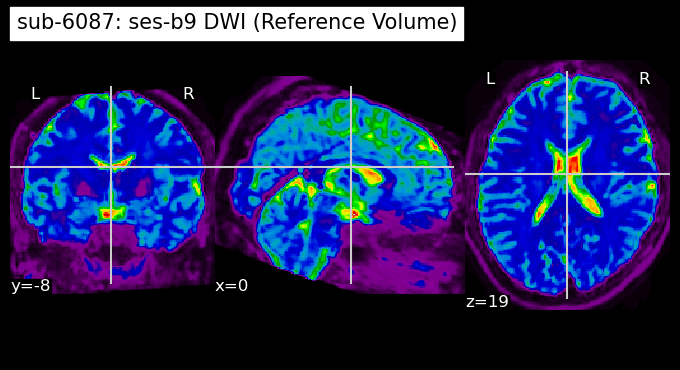

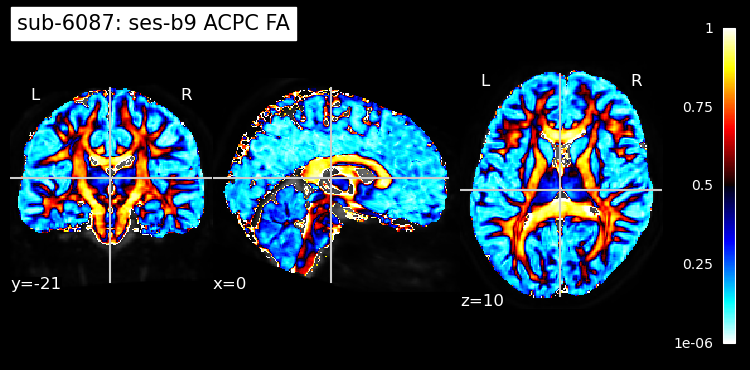

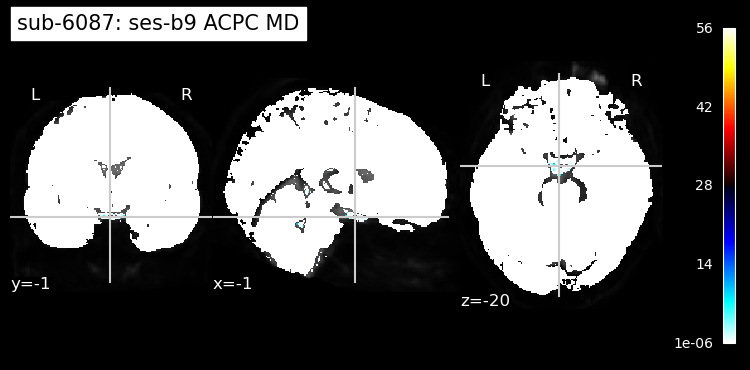

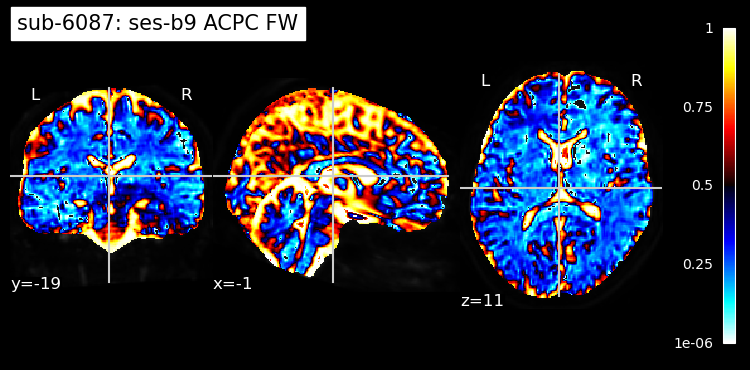

In [67]:
sub = random.choice(subs)
ses = f"ses-{baseline}"

qsiprep_path = f"{root}/{dataset}/derivatives/qsiprep/{sub}/{ses}/dwi"
qsiprep_anat_path = f"{root}/{dataset}/derivatives/qsiprep/{sub}/anat"
dwiref_path = f"{qsiprep_path}/{sub}_{ses}_dir-AP_space-ACPC_dwiref.nii.gz"
#wm_path = f"{qsiprep_anat_path}/{sub}_space-ACPC_label-DTIWM_dseg.nii.gz"
fa_path = f"{qsiprep_path}/{sub}_{ses}_dir-AP_space-ACPC_FA.nii.gz"
fw_path = f"{qsiprep_path}/{sub}_{ses}_dir-AP_space-ACPC_FW.nii.gz"

dwiref = nb.load(dwiref_path)

plot_epi(dwiref, title=f"{sub}: {ses} DWI (Reference Volume)")
#plot_roi(nb.load(wm_path), bg_img=dwiref, title=f"{sub}: {ses} Warped ACPC WM Mask")
plot_stat_map(nb.load(fa_path), bg_img=dwiref, title=f"{sub}: {ses} ACPC FA")
plot_stat_map(nb.load(md_path), bg_img=dwiref, title=f"{sub}: {ses} ACPC MD")
plot_stat_map(nb.load(fw_path), bg_img=dwiref, title=f"{sub}: {ses} ACPC FW")

#### Free Water Index

Finally, we can calculate the absolute and relative FW indices in the WM:

In [12]:
print("="*100)
for sub in subs:
    for ses in f"ses-{baseline}", f"ses-{sd}":
        
        # Parameters
        print(f"Subject: {sub}")
        print(f"Session : {ses}")
        ## FOLDERS
        qsiprep_path = f"{root}/{dataset}/derivatives/qsiprep/{sub}/{ses}/dwi"
        qsiprep_anat_path = f"{root}/{dataset}/derivatives/qsiprep/{sub}/anat"
        
        ## SCALARS & SEGS
        wm_path = get_fmriprep_data(sub, ses, "label-WM_probseg.nii.gz")
        csf_path = get_fmriprep_data(sub, ses, "label-CSF_probseg.nii.gz")
        fw_path = f"{dataset}/derivatives/qsiprep/{sub}/{ses}/dwi/{sub}_{ses}_space-MNI152NLin2009cAsym_FW.nii.gz"

        # Load FW scalar
        if os.path.exists(fw_path):
            fw = nb.load(fw_path)
        else:
            print(" No FW data found. Skipping...")
            continue
        fw_data = fw.get_fdata()

        # Load WM mask
        wm = nb.load(wm_path)
        wm_data = wm.get_fdata() >= 0.9 #only take voxels with high probability

        # Load CSF mask
        csf = nb.load(csf_path)
        csf_data = csf.get_fdata() >= 0.5

        # Create mask
        wm_mask = wm_data & (~csf_data) # remove the influence of CSF signals

        # Compute mean FW index
        fwwm = fw_data[wm_mask==1]
        fwwm_filtered = fwwm[fwwm < 0.8] # remove noise form borderline voxels
        np.median(fwwm), np.std(fwwm), np.histogram(fwwm)
        mean_fw_index = np.mean(fwwm_filtered)
        print(f"    Mean Free Water Index: {mean_fw_index}")

        # Compute relative FW index
        rel_fwwm = fwwm_filtered > 0.1
        rel_fw_index = np.sum(rel_fwwm) / np.sum(wm_mask == 1)
        print(f"    Relative Free Water Index: {rel_fw_index}")

        # Store output
        out_dict = {"participant_id" : [sub], "session" : [ses], "mfwi" : [mean_fw_index], "rfwi" : [rel_fw_index]}
        out_csv = pd.DataFrame(out_dict)
        out_csv.set_index("participant_id", inplace=True)
        out_csv.to_csv(f"{root}/{dataset}/derivatives/qsiprep/{sub}/{ses}/fw.stat.csv")
        print(f"Saved to qsiprep/{sub}/{ses}/fw.stat.csv")

        if baseline in ses:
            output_data.loc[sub, "mfwi_baseline"] = mean_fw_index
            output_data.loc[sub, "rfwi_baseline"] = rel_fw_index
        else:
            output_data.loc[sub, "mfwi_sd"] = mean_fw_index
            output_data.loc[sub, "rfwi_sd"] = rel_fw_index
        print("="*100)


Subject: sub-001
Session : ses-T1BL
    Mean Free Water Index: 0.21192501502984268
    Relative Free Water Index: 0.9804110561779744
Saved to qsiprep/sub-001/ses-T1BL/fw.stat.csv
Subject: sub-001
Session : ses-T2SD
    Mean Free Water Index: 0.20559806900458621
    Relative Free Water Index: 0.98635477582846
Saved to qsiprep/sub-001/ses-T2SD/fw.stat.csv
Subject: sub-003
Session : ses-T1BL
    Mean Free Water Index: 0.21223124806991633
    Relative Free Water Index: 0.9810851568390744
Saved to qsiprep/sub-003/ses-T1BL/fw.stat.csv
Subject: sub-003
Session : ses-T2SD
    Mean Free Water Index: 0.21231174910987985
    Relative Free Water Index: 0.9886186817409637
Saved to qsiprep/sub-003/ses-T2SD/fw.stat.csv
Subject: sub-004
Session : ses-T1BL
    Mean Free Water Index: 0.20818993997651397
    Relative Free Water Index: 0.971843801663484
Saved to qsiprep/sub-004/ses-T1BL/fw.stat.csv
Subject: sub-004
Session : ses-T2SD
    Mean Free Water Index: 0.2109064881218413
    Relative Free Water In

### 5. DTI-ALPS Index
This section uses the Liu & Barisano (2023) pipeline to calculate the DTI-ALPS index. First we clone the alps github into our code folder.

In [10]:
!git clone https://github.com/gbarisano/alps code/alps
!chmod +x code/alps/alps.sh

fatal: destination path 'code/alps' already exists and is not an empty directory.


The JHU atlas ROI for the bilateral SCR and SLF are included in the alps github folder. We need to resample these ROIs to the right dimensions to be able to use them with our preprocessed volumetric T1 image.

In [24]:
print("="*100)
rois = sorted(os.listdir("code/alps/ROIs_JHU_ALPS"))
out_rois = ["MNI_L_PROJ.nii.gz","MNI_L_ASSOC.nii.gz","MNI_R_PROJ.nii.gz","MNI_R_ASSOC.nii.gz"]

if all(roi in rois for roi in out_rois):
    raise Exception("ROIs already exist. No need to run this.")
    
labels = dict(zip(rois,out_rois))

for roi in rois:

    sub = random.choice(subs) # Random sub
    ses = f"ses-{baseline}"
    
    print(f"ROI: {roi}")
    fmriprep_path = f"{root}/{dataset}/derivatives/fmriprep/{sub}/{ses}/anat"

    resample_rois = (
        "antsApplyTransforms "
        "-d 3 "
        f"-i code/alps/ROIs_JHU_ALPS/{roi} "
        f"-r {fmriprep_path}/{sub}_{ses}_space-MNI152NLin2009cAsym_desc-preproc_T1w.nii.gz "
        f"-o code/alps/ROIs_JHU_ALPS/{labels[roi]} "
        "-n NearestNeighbor "
        "--verbose"
        )

    fmriprep_run = (
        "exec " # Singularity command
        f"-B {symlink},{work},{root}/{dataset},/opt/freesurfer/7.4/license.txt:/opt/freesurfer/license.txt "
        f"{fmriprep} " # We use the fmriprep container because it contains both Freesurfer and ANTS
        f"{resample_rois} "
        )

    submit("resample_rois", singularity, fmriprep_run)
    print("="*100)

Exception: ROIs already exist. No need to run this.

Select a random subject and print the DTI-ALPS ROIs

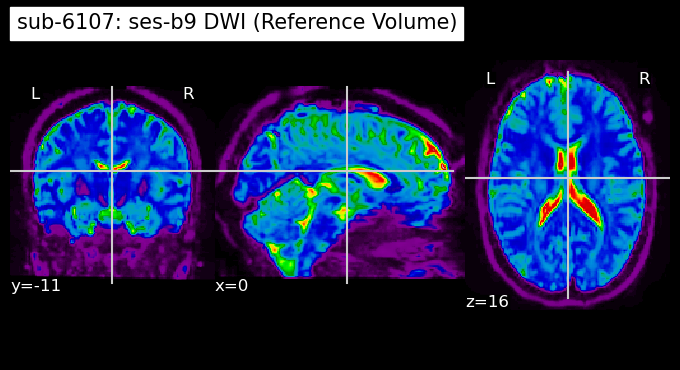

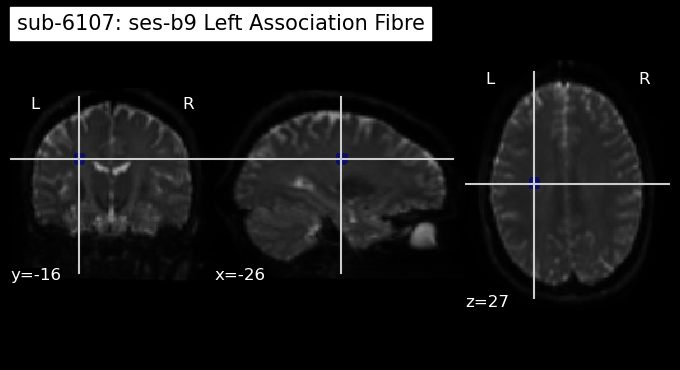

In [10]:
sub = random.choice(subs)
ses = f"ses-{baseline}"

dwiref_path = get_qsiprep_data(sub, ses, "dwiref.nii.gz")
roi_path = f"code/alps/ROIs_JHU_ALPS/L_SCR.nii.gz"

dwiref = nb.load(dwiref_path)

plot_epi(dwiref, title=f"{sub}: {ses} DWI (Reference Volume)")
plot_roi(nb.load(roi_path), bg_img=dwiref, title=f"{sub}: {ses} Left Association Fibre")

In [19]:
sub = "sub-6006"
ses = "ses-b9"

alps_root = f"{dataset}/derivatives/alps"
!mkdir -p $alps_root
fa = get_qsiprep_data(sub, ses, "FA.nii.gz")
md = get_qsiprep_data(sub, ses, "MD.nii.gz")
tensor = get_qsiprep_data(sub, ses, "FWTensor.nii.gz")

!cp $fa $alps_root/dti_FA.nii.gz
!cp $md $alps_root/dti_MD.nii.gz
!cp $tensor $alps_root/dti_tensor.nii.gz

In [20]:
dwi_img = nb.load(get_qsiprep_data(sub, ses, "desc-preproc_dwi.nii.gz"))
dwi_data = dwi_img.get_fdata()
bvals = np.loadtxt(get_qsiprep_data(sub, ses, "desc-preproc_dwi.bval"))

# Find b=0 indices (threshold = 50 s/mm² to allow small noise)
b0_indices = np.where(bvals < 50)[0]

# Extract b0 volumes and average them
b0_data = dwi_data[..., b0_indices]
b0_mean = np.mean(b0_data, axis=3)

# Save output
b0_img = nb.Nifti1Image(b0_mean, dwi_img.affine, dwi_img.header)
nb.save(b0_img, f"{alps_root}/b0.nii.gz")

In [11]:
print("="*100)
for sub in subs:
    for ses in f"ses-{baseline}", f"ses-{sd}":

        # Parameters
        print(f"Subject: {sub}")
        print(f"Session: {ses}")
                
        alps_run = (
            "code/alps/alps.sh "
            f"-a {get_qsiprep_data(sub, ses, 'desc-preproc_dwi.nii.gz')} "
            f"-b {get_qsiprep_data(sub, ses, 'desc-preproc_dwi.bval')} "
            f"-c {get_qsiprep_data(sub, ses, 'desc-preproc_dwi.bvec')} "
            "-d 0 "
            "-e 0 "
        )

        fsl_exec = (
            "exec " # Singularity command
            f"-B {symlink},{work},{root}/{dataset} "
            f"{fsl} " 
            f"{alps_run} "
        )

        submit("alps", singularity, fsl_exec)
        print("="*100)

Subject: sub-001
Session: ses-T1BL
Submitting job(s).
1 job(s) submitted to cluster 11165355.

Subject: sub-001
Session: ses-T2SD
Submitting job(s).
1 job(s) submitted to cluster 11165356.

Subject: sub-003
Session: ses-T1BL
Submitting job(s).
1 job(s) submitted to cluster 11165357.

Subject: sub-003
Session: ses-T2SD
Submitting job(s).
1 job(s) submitted to cluster 11165358.

Subject: sub-004
Session: ses-T1BL
Submitting job(s).
1 job(s) submitted to cluster 11165359.

Subject: sub-004
Session: ses-T2SD
Submitting job(s).
1 job(s) submitted to cluster 11165360.

Subject: sub-006
Session: ses-T1BL
Submitting job(s).
1 job(s) submitted to cluster 11165361.

Subject: sub-006
Session: ses-T2SD
Submitting job(s).
1 job(s) submitted to cluster 11165362.

Subject: sub-007
Session: ses-T1BL
Submitting job(s).
1 job(s) submitted to cluster 11165363.

Subject: sub-007
Session: ses-T2SD
Submitting job(s).
1 job(s) submitted to cluster 11165364.

Subject: sub-008
Session: ses-T1BL
Submitting job(

Move alps output to alps directory

In [12]:
alps_root = f"{dataset}/derivatives/alps"
!mkdir -p $alps_root

print("="*100)
for sub in subs:
    for ses in f"ses-{baseline}", f"ses-{sd}":

        # Parameters
        print(f"Subject: {sub}")
        print(f"Session: {ses}")

        old_alps_dir = f"{dataset}/derivatives/qsiprep/{sub}/{ses}/dwi/alps"
        new_alps_dir = f"{dataset}/derivatives/alps/{sub}/{ses}"
        !mkdir -p $new_alps_dir

        !mv $old_alps_dir/* $new_alps_dir/
        !rm -rf $old_alps_dir
        print("="*100)


Subject: sub-001
Session: ses-T1BL
Subject: sub-001
Session: ses-T2SD
mv: cannot move 'bruxelles-bids/derivatives/qsiprep/sub-001/ses-T2SD/dwi/alps/alps.stat' to 'bruxelles-bids/derivatives/alps/sub-001/ses-T2SD/alps.stat': Directory not empty
Subject: sub-003
Session: ses-T1BL
Subject: sub-003
Session: ses-T2SD
mv: cannot move 'bruxelles-bids/derivatives/qsiprep/sub-003/ses-T2SD/dwi/alps/alps.stat' to 'bruxelles-bids/derivatives/alps/sub-003/ses-T2SD/alps.stat': Directory not empty
Subject: sub-004
Session: ses-T1BL
Subject: sub-004
Session: ses-T2SD
mv: cannot move 'bruxelles-bids/derivatives/qsiprep/sub-004/ses-T2SD/dwi/alps/alps.stat' to 'bruxelles-bids/derivatives/alps/sub-004/ses-T2SD/alps.stat': Directory not empty
Subject: sub-006
Session: ses-T1BL
Subject: sub-006
Session: ses-T2SD
mv: cannot move 'bruxelles-bids/derivatives/qsiprep/sub-006/ses-T2SD/dwi/alps/alps.stat' to 'bruxelles-bids/derivatives/alps/sub-006/ses-T2SD/alps.stat': Directory not empty
Subject: sub-007
Session

In [13]:
print("="*100)
for sub in subs:
    for ses in f"ses-{baseline}", f"ses-{sd}":
        
        # Parameters
        print(f"Subject: {sub}")
        print(f"Session : {ses}")
        ## FOLDERS
        alps_path = f"{root}/{dataset}/derivatives/alps/{sub}/{ses}/alps.stat/alps.csv"

        # Display ALPS scores
        print("[1/2] Extracting ALPS scores")
        alps = pd.read_csv(f"{alps_path}")
        alps_index = alps.alps.item()

        print(f"    Left ALPS index: {alps.alps_L.item()}")
        print(f"    Right ALPS index: {alps.alps_R.item()}")
        print(f"    Mean ALPS index: {alps_index}")

        # Store in output
        print("[2/2] Storing in output")
        if baseline in ses:
            output_data.loc[sub, "alps_baseline"] = alps_index
        else:
            output_data.loc[sub, "alps_sd"] = alps_index
        print("="*100)
        

Subject: sub-001
Session : ses-T1BL
[1/2] Extracting ALPS scores
    Left ALPS index: 1.6701388888888888
    Right ALPS index: 1.5082956259426847
    Mean ALPS index: 1.5892172574157868
[2/2] Storing in output
Subject: sub-001
Session : ses-T2SD
[1/2] Extracting ALPS scores
    Left ALPS index: 1.2046511627906975
    Right ALPS index: 1.2305764411027569
    Mean ALPS index: 1.2176138019467273
[2/2] Storing in output
Subject: sub-003
Session : ses-T1BL
[1/2] Extracting ALPS scores
    Left ALPS index: 1.37146529562982
    Right ALPS index: 1.3633802816901408
    Mean ALPS index: 1.3674227886599803
[2/2] Storing in output
Subject: sub-003
Session : ses-T2SD
[1/2] Extracting ALPS scores
    Left ALPS index: 1.2247706422018347
    Right ALPS index: 1.260362694300518
    Mean ALPS index: 1.2425666682511765
[2/2] Storing in output
Subject: sub-004
Session : ses-T1BL
[1/2] Extracting ALPS scores
    Left ALPS index: 1.594427244582043
    Right ALPS index: 1.4345794392523363
    Mean ALPS inde

### 6. Exporting Output Data

This final section prepares the dataset for analysis in R. First, we create the output directory.

In [10]:
output_dir = f"outputs/{dataset}"
!mkdir -p $output_dir

Check if any indices are missing. This can happen if the notebook is run in parts and previous variables were removed from the workspace and/or from `output_data`. In the case of missing indices, can simply retrieve them from the `.csv` derivatives we saved earlier.

In [11]:
print("="*100)
for sub in subs:
    for ses in f"ses-{baseline}", f"ses-{sd}":
        
        # Parameters
        print(f"Subject: {sub}")
        print(f"Session : {ses}")
        # Indices Paths
        pvs_stats_path = f"{dataset}/derivatives/fmriprep/{sub}/{ses}/pvs.stat.csv"
        cp_stats_path = f"{dataset}/derivatives/fmriprep/{sub}/{ses}/cp.stat.csv"
        fw_stats_path = f"{dataset}/derivatives/qsiprep/{sub}/{ses}/fw.stat.csv"
        alps_stats_path = f"{dataset}/derivatives/alps/{sub}/{ses}/alps.stat/alps.csv"
        # Indices
        if baseline in ses:
            indices = ["pvsvf_baseline", "cpvf_baseline", "mfwi_baseline", "rfwi_baseline", "alps_baseline"]
        else:
            indices = ["pvsvf_sd", "cpvf_sd", "mfwi_sd", "rfwi_sd", "alps_sd"]
        sources = [pvs_stats_path, cp_stats_path, fw_stats_path, fw_stats_path, alps_stats_path]

        # Link indices to sources
        index_dict = dict(zip(indices,sources))
    
        print("Checking indices...")
        any_missing = False # Init
        for i in indices:
            if (i not in output_data.columns) or (pd.isna(output_data.loc[sub, i]) or (output_data.loc[sub, i] == "n/a")): # If the column doesn't exist or the cell has a "nan"
                print(f"    Index {i} missing")
                any_missing = True

                print(f"    Extracting {i} from {index_dict[i]}")
                
                if os.path.exists(index_dict[i]):
                    stats = pd.read_csv(index_dict[i]) # Load the correct .csv file
                else:
                    print(f"    No .CSV file found for {sub}, {ses}, {i}")
                    output_data.loc[sub, i] = "n/a"
                    continue
                
                label = i.split("_")[0] # Create a generic label that is able to find the right value in the dataframe
                value = stats[label].item()
                print(f"    {i} found: {value}")
                output_data.loc[sub, i] = stats[label].item()
                print(" "*100)

        if any_missing == False:
            print("All indices accounted for!")

        # Add dataset
        output_data["dataset"] = dataset

        print("="*100)

Subject: sub-001
Session : ses-T1BL
Checking indices...
    Index pvsvf_baseline missing
    Extracting pvsvf_baseline from bruxelles-bids/derivatives/fmriprep/sub-001/ses-T1BL/pvs.stat.csv
    pvsvf_baseline found: 0.0012149827114611
                                                                                                    
    Index cpvf_baseline missing
    Extracting cpvf_baseline from bruxelles-bids/derivatives/fmriprep/sub-001/ses-T1BL/cp.stat.csv
    cpvf_baseline found: 0.0005084642838189
                                                                                                    
    Index mfwi_baseline missing
    Extracting mfwi_baseline from bruxelles-bids/derivatives/qsiprep/sub-001/ses-T1BL/fw.stat.csv
    mfwi_baseline found: 0.2119250150298426
                                                                                                    
    Index rfwi_baseline missing
    Extracting rfwi_baseline from bruxelles-bids/derivatives/qsiprep/sub-001/ses-

We can have a quick look at the dataframe to see if everythings seems right:

In [33]:
output_data.head()

,site,group,age,sex,kss_score_baseline,kss_score_sd,chronotype,pvsvf_baseline,pvsvf_sd,cpvf_baseline,cpvf_sd,mfwi_baseline,rfwi_baseline,alps_baseline,mfwi_sd,rfwi_sd,alps_sd
participant_id,,,,,,,,,,,,,,,,,
sub-9001,Stockholm,3,25,M,4.333333,8.666667,2,0.001598,0.001705,0.000221,0.000236,n/a,n/a,n/a,n/a,n/a,n/a
sub-9002,Stockholm,3,70,M,3.000000,5.166667,2,0.000949,0.000873,0.000434,0.000481,n/a,n/a,n/a,n/a,n/a,n/a
sub-9003,Stockholm,3,70,M,4.000000,3.000000,3,0.001799,0.001704,0.000513,0.000474,n/a,n/a,n/a,n/a,n/a,n/a
sub-9004,Stockholm,3,70,F,5.833333,4.500000,2,0.002433,0.001874,0.000553,0.000667,n/a,n/a,n/a,n/a,n/a,n/a
sub-9005,Stockholm,3,70,M,5.166667,7.000000,1,0.002527,0.002534,0.000519,0.000529,n/a,n/a,n/a,n/a,n/a,n/a


Then, we export the `output_data` variable to a `.csv` file.

In [12]:
output_path = f"{output_dir}/{dataset}_dataframe.csv"
output_data.to_csv(output_path)
print(f"Output data saved to {output_path}")

Output data saved to outputs/bruxelles-bids/bruxelles-bids_dataframe.csv


### 7. Preparing the Master Dataframe

Once we have conducted the analyses on all datasets, we can collect our data in a "master" dataframe. 

In [38]:
datasets = sorted([d for d in os.listdir("outputs") if os.path.isdir(d)])
datasets

['bruxelles-bids',
 'juelich-petcoffee-bids',
 'juelich-sleepless-bids',
 'juelich-somnosafe-bids',
 'melbourne-bids',
 'montreal-bids',
 'ntnu-bids',
 'oslo-bids',
 'singapore-alfie-bids',
 'singapore-cheevul-bids',
 'singapore-effo2-bids',
 'stockholm-bids',
 'zurich-bids']

The Juelich somnosafe dataset has two different output dataframes. Let us quickly concatenate those:

In [39]:
d_path = "outputs/juelich-somnosafe-bids/juelich-somnosafe-bids_dataframe"
somno = pd.concat([pd.read_csv(d_path+"_group4.csv"), pd.read_csv(d_path+"_group7.csv")], ignore_index=True)
somno.rename(columns={"kss_score_tsd":"kss_score_followup"}, inplace=True) # Fix KSS naming
somno["dataset"] = "juelich-somnosafe-bids"
somno.to_csv(d_path+".csv")

Loop over datasets, concatenating them to the master dataframe:

In [40]:
master_data = pd.DataFrame()
for d in datasets:
    d_path = f"outputs/{d}/{d}_dataframe.csv"
    d_csv = pd.read_csv(d_path, index_col=False)

    if master_data.shape == (0, 0): # If the master dataframe is still empty
        master_data = d_csv
    else:
        master_data = pd.concat([master_data, d_csv], ignore_index=True)
master_data = master_data.iloc[:,:-1] # Remove last column
master_data

,participant_id,site,group,age,sex,kss_score_baseline,kss_score_sd,chronotype,pvsvf_baseline,cpvf_baseline,mfwi_baseline,rfwi_baseline,alps_baseline,dataset,pvsvf_sd,cpvf_sd,mfwi_sd,rfwi_sd,alps_sd,Unnamed: 0
0,sub-001,Bruxelles,4.0,19.000000,F,5.000000,7.000000,1.0,0.001215,0.000508,0.211925,0.980411,1.589217,bruxelles-bids,0.001143,0.000565,0.205598,0.986355,1.217614,NaN
1,sub-003,Bruxelles,4.0,21.000000,F,3.000000,9.000000,1.0,0.001439,0.000182,0.212231,0.981085,1.367423,bruxelles-bids,0.001956,0.000294,0.212312,0.988619,1.242567,NaN
2,sub-004,Bruxelles,4.0,19.000000,F,1.000000,6.000000,3.0,0.001085,0.000288,0.208190,0.971844,1.514503,bruxelles-bids,0.001032,0.000265,0.210906,0.985100,1.095042,NaN
3,sub-006,Bruxelles,4.0,29.000000,F,2.000000,5.000000,3.0,0.000563,0.000224,0.213292,0.978142,1.426030,bruxelles-bids,0.000443,0.000231,0.212940,0.984775,1.098525,NaN
4,sub-007,Bruxelles,4.0,20.000000,F,1.000000,6.000000,3.0,0.000742,0.000272,0.208765,0.980243,1.527862,bruxelles-bids,0.000687,0.000241,0.201507,0.985387,1.347277,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
424,sub-137,Zurich,4.0,23.052704,M,4.142857,7.571429,3.0,0.000922,0.000397,NaN,NaN,NaN,zurich-bids,0.000464,0.000364,NaN,NaN,NaN,NaN
425,sub-138,Zurich,4.0,26.762491,M,2.857143,4.142857,1.0,0.000560,0.000267,NaN,NaN,NaN,zurich-bids,0.000510,0.000302,NaN,NaN,NaN,NaN
426,sub-140,Zurich,4.0,25.752225,M,3.285714,6.285714,3.0,0.001232,0.000377,NaN,NaN,NaN,zurich-bids,0.001149,0.000401,NaN,NaN,NaN,NaN
427,sub-141,Zurich,4.0,21.815195,M,2.857143,4.666667,3.0,0.000518,0.000345,NaN,NaN,NaN,zurich-bids,0.000438,0.000328,NaN,NaN,NaN,NaN


Collect the correct baseline and follow-up session labels and store them in a LUT:

In [41]:
BASELINE_TYPE_PRIORITY = {"b_prefix": 0, "BL": 0, "RC": 1}
FOLLOWUP_TYPE_PRIORITY = {"sd_prefix": 0, "SD": 0, "CL": 1, "SR": 2}

# Only needed when two candidates of the SAME type/priority tie for a subject
BASELINE_OVERRIDES = {
    "juelich-somnosafe-bids": "ses-T2BL",
    "oslo-bids": "ses-b9",
}
FOLLOWUP_OVERRIDES = {
    "oslo-bids": "ses-sd9",
}


def classify_session(ses):
    s = ses.lower()
    if re.match(r"^ses-b", s):
        return "baseline", "b_prefix"
    if re.match(r"^ses-t\d+bl$", s):
        return "baseline", "BL"
    if re.match(r"^ses-t\d+rc$", s):
        return "baseline", "RC"
    if re.match(r"^ses-sd", s):
        return "followup", "sd_prefix"
    if re.match(r"^ses-t\d+sd$", s):
        return "followup", "SD"
    if re.match(r"^ses-t\d+cl$", s):
        return "followup", "CL"
    if re.match(r"^ses-t\d+sr$", s):
        return "followup", "SR"
    return "unmatched", None


def select_session(candidates, dataset, overrides, type_priority, label, pid):
    """candidates: list of (session_name, subtype). Picks one, or None if empty."""
    if not candidates:
        return None
    if len(candidates) == 1:
        return candidates[0][0]

    names = [c[0] for c in candidates]

    if dataset in overrides and overrides[dataset] in names:
        return overrides[dataset]

    ranked = sorted(candidates, key=lambda c: type_priority.get(c[1], 99))
    best = type_priority.get(ranked[0][1], 99)
    tied = [c for c in ranked if type_priority.get(c[1], 99) == best]

    if len(tied) == 1:
        return tied[0][0]

    chosen = sorted(n for n, _ in tied)[0]
    print(f"  [AMBIGUOUS {label}] {pid} ({dataset}): {names} -> defaulting to {chosen}, add an override if wrong")
    return chosen


def scan_all_sessions(root, master_data):
    """Full scan, run once. Returns a lookup DataFrame keyed by (dataset, participant_id)."""
    records = []
    for _, row in master_data.iterrows():
        pid, d = row["participant_id"], row["dataset"]
        subj_dir = f"{root}/{d}/{pid}"

        if not os.path.isdir(subj_dir):
            print(f"  [NO SUBJECT DIR] {pid} ({d}): {subj_dir}")
            records.append({"participant_id": pid, "dataset": d, "baseline_session": None, "followup_session": None})
            continue

        sessions = [
            e for e in os.listdir(subj_dir)
            if e.startswith("ses-") and os.path.isdir(os.path.join(subj_dir, e))
        ]

        baseline_candidates, followup_candidates, unmatched = [], [], []
        for ses in sessions:
            kind, subtype = classify_session(ses)
            if kind == "baseline":
                baseline_candidates.append((ses, subtype))
            elif kind == "followup":
                followup_candidates.append((ses, subtype))
            elif kind == "unmatched":
                unmatched.append(ses)
            # kind == "ignore" (RC) is dropped silently

        if unmatched:
            print(f"  [UNMATCHED] {pid} ({d}): {unmatched}")

        bl = select_session(baseline_candidates, d, BASELINE_OVERRIDES, BASELINE_TYPE_PRIORITY, "baseline", pid)
        fu = select_session(followup_candidates, d, FOLLOWUP_OVERRIDES, FOLLOWUP_TYPE_PRIORITY, "follow-up", pid)

        if bl is None:
            print(f"  [NO BASELINE] {pid} ({d}): sessions present = {sessions}")
        if fu is None:
            print(f"  [NO FOLLOWUP] {pid} ({d}): sessions present = {sessions}")

        records.append({"participant_id": pid, "dataset": d, "baseline_session": bl, "followup_session": fu})

    return pd.DataFrame(records)


sessions_df = scan_all_sessions(root, master_data).set_index(["dataset", "participant_id"])

print("\n=== Session scan summary ===")
print(f"Total subjects: {len(sessions_df)}")
print(f"No baseline resolved: {sessions_df['baseline_session'].isna().sum()}")
print(f"No follow-up resolved: {sessions_df['followup_session'].isna().sum()}")

  [AMBIGUOUS follow-up] sub-180 (juelich-sleepless-bids): ['ses-sd', 'ses-T2SD'] -> defaulting to ses-T2SD, add an override if wrong
  [AMBIGUOUS follow-up] sub-204 (juelich-sleepless-bids): ['ses-sd', 'ses-T2SD'] -> defaulting to ses-T2SD, add an override if wrong
  [AMBIGUOUS follow-up] sub-207 (juelich-sleepless-bids): ['ses-T2SD', 'ses-sd'] -> defaulting to ses-T2SD, add an override if wrong
  [AMBIGUOUS follow-up] sub-259 (juelich-sleepless-bids): ['ses-T2SD', 'ses-sd'] -> defaulting to ses-T2SD, add an override if wrong
  [AMBIGUOUS follow-up] sub-280 (juelich-sleepless-bids): ['ses-T2SD', 'ses-sd'] -> defaulting to ses-T2SD, add an override if wrong
  [AMBIGUOUS follow-up] sub-321 (juelich-sleepless-bids): ['ses-T2SD', 'ses-sd'] -> defaulting to ses-T2SD, add an override if wrong
  [AMBIGUOUS follow-up] sub-322 (juelich-sleepless-bids): ['ses-sd', 'ses-T2SD'] -> defaulting to ses-T2SD, add an override if wrong
  [AMBIGUOUS follow-up] sub-332 (juelich-sleepless-bids): ['ses-T2SD'

We will retrieve some additional demographic data from participants.tsv files.

In [42]:
for d in datasets:
    tsv_path = f"{d}/participants.tsv"
    !datalad get $tsv_path
    tsv = pd.read_csv(tsv_path, sep="\t", dtype={"participant_id": str})
    tsv['participant_id'] = tsv['participant_id'].str.strip()

    mask = master_data["dataset"] == d
    for col in ['psqi_score', 'bmi', 'handedness']:
        if col in tsv.columns:
            master_data.loc[mask, col] = master_data.loc[mask, 'participant_id'].map(
                tsv.set_index("participant_id")[col]
            )
master_data

action summary:
  get (notneeded: 2)
action summary:
  get (notneeded: 2)
action summary:
  get (notneeded: 2)
action summary:
  get (notneeded: 2)
action summary:
  get (notneeded: 2)
action summary:
  get (notneeded: 2)
action summary:
  get (notneeded: 2)
action summary:
  get (notneeded: 2)
action summary:
  get (notneeded: 2)
action summary:
  get (notneeded: 2)
action summary:
  get (notneeded: 2)
action summary:
  get (notneeded: 2)
action summary:
  get (notneeded: 2)


,participant_id,site,group,age,sex,kss_score_baseline,kss_score_sd,chronotype,pvsvf_baseline,cpvf_baseline,...,dataset,pvsvf_sd,cpvf_sd,mfwi_sd,rfwi_sd,alps_sd,Unnamed: 0,psqi_score,bmi,handedness
0,sub-001,Bruxelles,4.0,19.000000,F,5.000000,7.000000,1.0,0.001215,0.000508,...,bruxelles-bids,0.001143,0.000565,0.205598,0.986355,1.217614,NaN,3.0,18.510000,L
1,sub-003,Bruxelles,4.0,21.000000,F,3.000000,9.000000,1.0,0.001439,0.000182,...,bruxelles-bids,0.001956,0.000294,0.212312,0.988619,1.242567,NaN,3.0,25.040000,R
2,sub-004,Bruxelles,4.0,19.000000,F,1.000000,6.000000,3.0,0.001085,0.000288,...,bruxelles-bids,0.001032,0.000265,0.210906,0.985100,1.095042,NaN,4.0,20.480000,R
3,sub-006,Bruxelles,4.0,29.000000,F,2.000000,5.000000,3.0,0.000563,0.000224,...,bruxelles-bids,0.000443,0.000231,0.212940,0.984775,1.098525,NaN,1.0,21.050000,R
4,sub-007,Bruxelles,4.0,20.000000,F,1.000000,6.000000,3.0,0.000742,0.000272,...,bruxelles-bids,0.000687,0.000241,0.201507,0.985387,1.347277,NaN,3.0,24.860000,R
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
424,sub-137,Zurich,4.0,23.052704,M,4.142857,7.571429,3.0,0.000922,0.000397,...,zurich-bids,0.000464,0.000364,NaN,NaN,NaN,NaN,3.0,23.388687,NaN
425,sub-138,Zurich,4.0,26.762491,M,2.857143,4.142857,1.0,0.000560,0.000267,...,zurich-bids,0.000510,0.000302,NaN,NaN,NaN,NaN,3.0,23.765432,NaN
426,sub-140,Zurich,4.0,25.752225,M,3.285714,6.285714,3.0,0.001232,0.000377,...,zurich-bids,0.001149,0.000401,NaN,NaN,NaN,NaN,1.0,22.395413,NaN
427,sub-141,Zurich,4.0,21.815195,M,2.857143,4.666667,3.0,0.000518,0.000345,...,zurich-bids,0.000438,0.000328,NaN,NaN,NaN,NaN,6.0,25.099502,NaN


Add time of scan:

In [43]:
OUTPUT_DIR = "./outputs"
CACHE_PATH = os.path.join(OUTPUT_DIR, "all_participants_collection_times.csv")
os.makedirs(OUTPUT_DIR, exist_ok=True)

FORCE_REFRESH = False # Set to true to obtain a refresh of the data. Otherwise, load.

_csv_cache = {}


def load_collection_times_csv(root, d):
    """Load and cache [dataset]/derivatives/collection_times.csv, keyed by participant_id."""
    if d in _csv_cache:
        return _csv_cache[d]

    csv_path = os.path.join(root, d, "derivatives", "collection_times.csv")
    if not os.path.exists(csv_path):
        print(f"  [CSV MISSING] {d}: no file at {csv_path}")
        _csv_cache[d] = None
        return None

    try:
        df = pd.read_csv(csv_path, dtype=str, sep=None, engine="python")
    except Exception as e:
        print(f"  [CSV UNREADABLE] {d}: {e}")
        _csv_cache[d] = None
        return None

    df.columns = [c.strip() for c in df.columns]

    if "participant_id" not in df.columns:
        print(f"  [CSV MALFORMED] {d}: missing 'participant_id' column (found: {list(df.columns)})")
        _csv_cache[d] = None
        return None

    df["participant_id"] = df["participant_id"].astype(str).str.strip()

    dupes = df["participant_id"][df["participant_id"].duplicated()]
    if len(dupes) > 0:
        print(f"  [CSV WARNING] {d}: duplicate participant_id values: {list(dupes.unique())}")

    df = df.set_index("participant_id")
    _csv_cache[d] = df
    return df


def csv_fallback_time(root, d, pid, timepoint):
    """timepoint is 'time_bl' or 'time_sd'. Returns (time_or_None, reason_if_failed)."""
    df = load_collection_times_csv(root, d)
    if df is None:
        return None, "csv fallback unavailable (missing/unreadable file)"
    if pid not in df.index:
        return None, "participant not found in collection_times.csv"
    if timepoint not in df.columns:
        return None, f"csv missing '{timepoint}' column"

    val = df.at[pid, timepoint]
    if pd.isna(val) or str(val).strip() == "":
        return None, f"csv '{timepoint}' value empty for this participant"

    return str(val).strip(), None


def find_json_path(root, d, pid, ses):
    if ses is None:
        return None
    anat_dir = f"{root}/{d}/{pid}/{ses}/anat"
    if not os.path.isdir(anat_dir):
        return None
    for filename in (f"{pid}_{ses}_T1w.json", f"{pid}_{ses}_run-1_T1w.json", f"{pid}_{ses}_run-01_T1w.json"):
        path = os.path.join(anat_dir, filename)
        if os.path.lexists(path):
            return path
    return None


def extract_acquisition_time(json_path):
    if not os.path.exists(json_path) or os.path.getsize(json_path) == 0:
        return None, "file missing or empty after get"
    try:
        with open(json_path) as f:
            data = json.load(f)
    except json.JSONDecodeError:
        return None, "invalid JSON (likely un-fetched annex pointer)"

    time_str = data.get("AcquisitionTime", "")
    if not time_str:
        return None, "AcquisitionTime key missing or empty"

    if ":" in time_str:
        parts = time_str.split(":")
        return (":".join(parts[:2]), None) if len(parts) >= 2 else (None, f"unparseable time: {time_str!r}")
    if len(time_str) < 4:
        return None, f"time string too short: {time_str!r}"
    return f"{time_str[:2]}:{time_str[2:4]}", None


def batched_datalad(cmd, paths, batch_size=200):
    """Run datalad get/drop across many paths in large batches instead of one-by-one."""
    for i in range(0, len(paths), batch_size):
        batch = paths[i:i + batch_size]
        result = subprocess.run(["datalad", cmd] + batch, capture_output=True, text=True)
        if result.returncode != 0:
            print(f"  [datalad {cmd} FAILED on batch {i}-{i+len(batch)}] stderr: {result.stderr.strip()[:300]}")


# ---- Load from cache if available, otherwise run the full extraction ----
if os.path.exists(CACHE_PATH) and not FORCE_REFRESH:
    print(f"[CACHE] Loading collection times from {CACHE_PATH} instead of recomputing")
    cached = pd.read_csv(CACHE_PATH, dtype=str)

    master_data = master_data.merge(
        cached[["participant_id", "dataset", "time_bl", "time_sd"]],
        on=["participant_id", "dataset"],
        how="left"
    )

    n = len(master_data)
    missing_bl = master_data["time_bl"].isna().sum()
    missing_sd = master_data["time_sd"].isna().sum()
    print(f"Loaded {n} subjects from cache. Missing time_bl: {missing_bl}, time_sd: {missing_sd}")

else:
    master_data["time_bl"] = None
    master_data["time_sd"] = None

    # ---- Step 1: figure out every path we need, using the cached sessions_df ----
    plan = []
    no_path_cases = []

    for idx, row in master_data.iterrows():
        pid, d = row["participant_id"], row["dataset"]
        bl_ses = sessions_df.loc[(d, pid), "baseline_session"]
        fu_ses = sessions_df.loc[(d, pid), "followup_session"]

        bl_path = find_json_path(root, d, pid, bl_ses)
        fu_path = find_json_path(root, d, pid, fu_ses)

        if bl_ses is None:
            no_path_cases.append((idx, "bl", "no session resolved"))
        elif bl_path is None:
            no_path_cases.append((idx, "bl", f"no T1w JSON found in {bl_ses}/anat"))
        else:
            plan.append((idx, "bl", bl_path))

        if fu_ses is None:
            no_path_cases.append((idx, "sd", "no session resolved"))
        elif fu_path is None:
            no_path_cases.append((idx, "sd", f"no T1w JSON found in {fu_ses}/anat"))
        else:
            plan.append((idx, "sd", fu_path))

    all_paths = [p for _, _, p in plan]
    print(f"\nFetching {len(all_paths)} files in batches...")

    # ---- Step 2: one batched get, one batched drop ----
    batched_datalad("get", all_paths)

    fail_count_bl = 0
    fail_count_sd = 0
    csv_recovered_bl = 0
    csv_recovered_sd = 0

    def apply_csv_fallback(idx, timepoint, json_reason):
        pid, d = master_data.at[idx, "participant_id"], master_data.at[idx, "dataset"]
        col = "time_bl" if timepoint == "bl" else "time_sd"
        label = "BL" if timepoint == "bl" else "SD"

        csv_val, csv_reason = csv_fallback_time(root, d, pid, col)
        if csv_val is not None:
            master_data.at[idx, col] = csv_val
            print(f"[{label} CSV RECOVERED] {pid} ({d}): json failed ({json_reason}); using csv value {csv_val}")
            return csv_val, True

        print(f"[{label} FAIL] {pid} ({d}): json failed ({json_reason}); csv fallback also failed ({csv_reason})")
        return None, False

    for idx, timepoint, reason in no_path_cases:
        _, recovered = apply_csv_fallback(idx, timepoint, reason)
        if timepoint == "bl":
            csv_recovered_bl += 1 if recovered else 0
            fail_count_bl += 0 if recovered else 1
        else:
            csv_recovered_sd += 1 if recovered else 0
            fail_count_sd += 0 if recovered else 1

    for idx, timepoint, path in plan:
        t, reason = extract_acquisition_time(path)
        col = "time_bl" if timepoint == "bl" else "time_sd"

        if t is not None:
            master_data.at[idx, col] = t
            continue

        _, recovered = apply_csv_fallback(idx, timepoint, reason)
        if timepoint == "bl":
            csv_recovered_bl += 1 if recovered else 0
            fail_count_bl += 0 if recovered else 1
        else:
            csv_recovered_sd += 1 if recovered else 0
            fail_count_sd += 0 if recovered else 1

    batched_datalad("drop", all_paths)

    # ---- Hardcoded override: Melbourne acquisition times are documented as 13:45 for all subjects ----
    melbourne_mask = master_data["dataset"] == "melbourne-bids"
    master_data.loc[melbourne_mask, "time_bl"] = "13:45"
    master_data.loc[melbourne_mask, "time_sd"] = "13:45"
    print(f"\n[OVERRIDE] Set time_bl and time_sd to 13:45 for {melbourne_mask.sum()} melbourne-bids subjects")

    # ---- Save so this doesn't need to run again ----
    master_data[["participant_id", "dataset", "time_bl", "time_sd"]].to_csv(CACHE_PATH, index=False)
    print(f"\n[CACHE] Saved collection times to {CACHE_PATH}")

# ---- Final summary (runs whether loaded from cache or freshly computed) ----
n = len(master_data)
final_missing_bl = master_data["time_bl"].isna().sum()
final_missing_sd = master_data["time_sd"].isna().sum()

print("\n=== Final Summary ===")
print(f"Total subjects: {n}")
print(f"Missing time_bl: {final_missing_bl} ({final_missing_bl/n:.1%})")
print(f"Missing time_sd: {final_missing_sd} ({final_missing_sd/n:.1%})")

master_data.head()

[CACHE] Loading collection times from ./outputs/all_participants_collection_times.csv instead of recomputing
Loaded 429 subjects from cache. Missing time_bl: 81, time_sd: 81

=== Final Summary ===
Total subjects: 429
Missing time_bl: 81 (18.9%)
Missing time_sd: 81 (18.9%)


,participant_id,site,group,age,sex,kss_score_baseline,kss_score_sd,chronotype,pvsvf_baseline,cpvf_baseline,...,cpvf_sd,mfwi_sd,rfwi_sd,alps_sd,Unnamed: 0,psqi_score,bmi,handedness,time_bl,time_sd
0,sub-001,Bruxelles,4.0,19.0,F,5.0,7.0,1.0,0.001215,0.000508,...,0.000565,0.205598,0.986355,1.217614,NaN,3.0,18.51,L,17:06,09:30
1,sub-003,Bruxelles,4.0,21.0,F,3.0,9.0,1.0,0.001439,0.000182,...,0.000294,0.212312,0.988619,1.242567,NaN,3.0,25.04,R,16:47,09:01
2,sub-004,Bruxelles,4.0,19.0,F,1.0,6.0,3.0,0.001085,0.000288,...,0.000265,0.210906,0.985100,1.095042,NaN,4.0,20.48,R,15:49,08:28
3,sub-006,Bruxelles,4.0,29.0,F,2.0,5.0,3.0,0.000563,0.000224,...,0.000231,0.212940,0.984775,1.098525,NaN,1.0,21.05,R,16:48,09:22
4,sub-007,Bruxelles,4.0,20.0,F,1.0,6.0,3.0,0.000742,0.000272,...,0.000241,0.201507,0.985387,1.347277,NaN,3.0,24.86,R,15:48,08:30


Add psychomotor vigilance task mean reaction time:

In [44]:
# Add new columns
master_data["pvt_meanrt_bl"] = None
master_data["pvt_meanrt_followup"] = None
master_data["pvt_meanrs_bl"] = None
master_data["pvt_meanrs_followup"] = None

RS_DATASETS = ["juelich-petcoffee-bids", "juelich-sleepless-bids", "juelich-somnosafe-bids", "melbourne-bids"]

def pvt_var_stub(d):
    return "pvt_meanrs" if d in RS_DATASETS else "pvt_meanrt"

def get_pvt_keys(d):
    # only look for the CORRECT stub for this dataset — no cross-fallback to the other measure
    stub = pvt_var_stub(d)
    baseline_keys = [f"{stub}_baseline", f"{stub}_recovery"]
    followup_keys = [f"{stub}_followup", f"{stub}_tsd", f"{stub}_psd", f"{stub}_cl", f"{stub}_sd"]
    return baseline_keys, followup_keys


no_data_bl = 0
no_data_followup = 0
no_session_bl = 0
no_session_followup = 0

for d in datasets:
    participants_path = os.path.join(root, d, "participants.tsv")
    if not os.path.exists(participants_path):
        print(f"Missing participants.tsv for dataset {d}")
        continue

    df_p = pd.read_csv(participants_path, sep="\t")

    if "participant_id" not in df_p.columns:
        print(f"participants.tsv in {d} lacks participant_id column")
        continue

    baseline_keys, followup_keys = get_pvt_keys(d)
    is_rs = d in RS_DATASETS
    bl_col = "pvt_meanrs_bl" if is_rs else "pvt_meanrt_bl"
    followup_col = "pvt_meanrs_followup" if is_rs else "pvt_meanrt_followup"

    mask = master_data["dataset"] == d
    for idx, row in master_data[mask].iterrows():
        pid = row["participant_id"]

        # use the session lookup table as the source of truth for whether
        # a baseline/follow-up visit actually exists for this subject
        bl_ses = sessions_df.loc[(d, pid), "baseline_session"] if (d, pid) in sessions_df.index else None
        fu_ses = sessions_df.loc[(d, pid), "followup_session"] if (d, pid) in sessions_df.index else None

        row_p = df_p.loc[df_p["participant_id"] == pid]
        if row_p.empty:
            continue

        row_p = row_p.iloc[0]

        # ---- baseline ----
        if bl_ses is None:
            no_session_bl += 1
        else:
            pvt_bl_raw = None
            for key in baseline_keys:
                if key in row_p and pd.notna(row_p[key]):
                    pvt_bl_raw = row_p[key]
                    break
            if pvt_bl_raw is None:
                no_data_bl += 1

            # straight copy, no normalization
            master_data.at[idx, bl_col] = pvt_bl_raw

        # ---- follow-up ----
        if fu_ses is None:
            no_session_followup += 1
        else:
            pvt_fu_raw = None
            for key in followup_keys:
                if key in row_p and pd.notna(row_p[key]):
                    pvt_fu_raw = row_p[key]
                    break
            if pvt_fu_raw is None:
                no_data_followup += 1

            # straight copy, no normalization
            master_data.at[idx, followup_col] = pvt_fu_raw

# check results
n = len(master_data)
print("\n=== PVT extraction summary ===")
print(f"Total subjects: {n}")
print(f"Baseline: {no_data_bl} had a resolved session but no PVT value; {no_session_bl} had no baseline session at all")
print(f"Follow-up: {no_data_followup} had a resolved session but no PVT value; {no_session_followup} had no follow-up session at all")

master_data.head()



=== PVT extraction summary ===
Total subjects: 429
Baseline: 227 had a resolved session but no PVT value; 0 had no baseline session at all
Follow-up: 227 had a resolved session but no PVT value; 0 had no follow-up session at all


,participant_id,site,group,age,sex,kss_score_baseline,kss_score_sd,chronotype,pvsvf_baseline,cpvf_baseline,...,Unnamed: 0,psqi_score,bmi,handedness,time_bl,time_sd,pvt_meanrt_bl,pvt_meanrt_followup,pvt_meanrs_bl,pvt_meanrs_followup
0,sub-001,Bruxelles,4.0,19.0,F,5.0,7.0,1.0,0.001215,0.000508,...,NaN,3.0,18.51,L,17:06,09:30,None,None,None,None
1,sub-003,Bruxelles,4.0,21.0,F,3.0,9.0,1.0,0.001439,0.000182,...,NaN,3.0,25.04,R,16:47,09:01,None,None,None,None
2,sub-004,Bruxelles,4.0,19.0,F,1.0,6.0,3.0,0.001085,0.000288,...,NaN,4.0,20.48,R,15:49,08:28,None,None,None,None
3,sub-006,Bruxelles,4.0,29.0,F,2.0,5.0,3.0,0.000563,0.000224,...,NaN,1.0,21.05,R,16:48,09:22,None,None,None,None
4,sub-007,Bruxelles,4.0,20.0,F,1.0,6.0,3.0,0.000742,0.000272,...,NaN,3.0,24.86,R,15:48,08:30,None,None,None,None


To avoid duplicate participant IDs, we generate a new ID for each subject that includes their site:

In [45]:
for row in master_data.index: # Loop over rows
    sub = master_data.iloc[row,:].participant_id # Obtain the subject ID
    site = str(master_data.iloc[row,:].dataset) # Obtain the site
    labels = site.split("-")[:-1] # Split the site into sublabels

    if len(labels) > 1: # If there are more than two sub-labels
        prefix = (labels[0][:2]+labels[1][:2]).upper() # Take the first two letters of the first two sub-labels
    else:
        prefix = site[:4].upper() # Take the first four letters of the site

    suffix = sub.replace("sub-","") # Take the subject ID
    
    new_sub = f"sub-{prefix}{suffix}" # Create new subject ID
    master_data.iloc[row,0] = new_sub # Insert into dataframe

master_data

,participant_id,site,group,age,sex,kss_score_baseline,kss_score_sd,chronotype,pvsvf_baseline,cpvf_baseline,...,Unnamed: 0,psqi_score,bmi,handedness,time_bl,time_sd,pvt_meanrt_bl,pvt_meanrt_followup,pvt_meanrs_bl,pvt_meanrs_followup
0,sub-BRUX001,Bruxelles,4.0,19.000000,F,5.000000,7.000000,1.0,0.001215,0.000508,...,NaN,3.0,18.510000,L,17:06,09:30,None,None,None,None
1,sub-BRUX003,Bruxelles,4.0,21.000000,F,3.000000,9.000000,1.0,0.001439,0.000182,...,NaN,3.0,25.040000,R,16:47,09:01,None,None,None,None
2,sub-BRUX004,Bruxelles,4.0,19.000000,F,1.000000,6.000000,3.0,0.001085,0.000288,...,NaN,4.0,20.480000,R,15:49,08:28,None,None,None,None
3,sub-BRUX006,Bruxelles,4.0,29.000000,F,2.000000,5.000000,3.0,0.000563,0.000224,...,NaN,1.0,21.050000,R,16:48,09:22,None,None,None,None
4,sub-BRUX007,Bruxelles,4.0,20.000000,F,1.000000,6.000000,3.0,0.000742,0.000272,...,NaN,3.0,24.860000,R,15:48,08:30,None,None,None,None
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
424,sub-ZURI137,Zurich,4.0,23.052704,M,4.142857,7.571429,3.0,0.000922,0.000397,...,NaN,3.0,23.388687,NaN,13:43,13:50,None,None,None,None
425,sub-ZURI138,Zurich,4.0,26.762491,M,2.857143,4.142857,1.0,0.000560,0.000267,...,NaN,3.0,23.765432,NaN,13:21,13:13,None,None,None,None
426,sub-ZURI140,Zurich,4.0,25.752225,M,3.285714,6.285714,3.0,0.001232,0.000377,...,NaN,1.0,22.395413,NaN,13:26,13:20,None,None,None,None
427,sub-ZURI141,Zurich,4.0,21.815195,M,2.857143,4.666667,3.0,0.000518,0.000345,...,NaN,6.0,25.099502,NaN,13:51,14:17,None,None,None,None


For clarity, we also add the sleep deprivation (SD) vs. sleep restriction (SR) protocol:

In [46]:
master_data["protocol"] = np.nan
master_data.loc[master_data['group'] == 1, 'group'] = 2 # Consistent labeling across control groups
master_data.loc[master_data["group"] == 2, "protocol"] = "CT"
master_data.loc[master_data["group"] == 3, "protocol"] = "SR"
master_data.loc[master_data["group"] == 4, "protocol"] = "SD"
master_data.loc[master_data["group"] == 7, "protocol"] = "SD"

master_data

/tmp/ipykernel_2618314/1460961889.py:3: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'CT' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  master_data.loc[master_data["group"] == 2, "protocol"] = "CT"


,participant_id,site,group,age,sex,kss_score_baseline,kss_score_sd,chronotype,pvsvf_baseline,cpvf_baseline,...,psqi_score,bmi,handedness,time_bl,time_sd,pvt_meanrt_bl,pvt_meanrt_followup,pvt_meanrs_bl,pvt_meanrs_followup,protocol
0,sub-BRUX001,Bruxelles,4.0,19.000000,F,5.000000,7.000000,1.0,0.001215,0.000508,...,3.0,18.510000,L,17:06,09:30,None,None,None,None,SD
1,sub-BRUX003,Bruxelles,4.0,21.000000,F,3.000000,9.000000,1.0,0.001439,0.000182,...,3.0,25.040000,R,16:47,09:01,None,None,None,None,SD
2,sub-BRUX004,Bruxelles,4.0,19.000000,F,1.000000,6.000000,3.0,0.001085,0.000288,...,4.0,20.480000,R,15:49,08:28,None,None,None,None,SD
3,sub-BRUX006,Bruxelles,4.0,29.000000,F,2.000000,5.000000,3.0,0.000563,0.000224,...,1.0,21.050000,R,16:48,09:22,None,None,None,None,SD
4,sub-BRUX007,Bruxelles,4.0,20.000000,F,1.000000,6.000000,3.0,0.000742,0.000272,...,3.0,24.860000,R,15:48,08:30,None,None,None,None,SD
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
424,sub-ZURI137,Zurich,4.0,23.052704,M,4.142857,7.571429,3.0,0.000922,0.000397,...,3.0,23.388687,NaN,13:43,13:50,None,None,None,None,SD
425,sub-ZURI138,Zurich,4.0,26.762491,M,2.857143,4.142857,1.0,0.000560,0.000267,...,3.0,23.765432,NaN,13:21,13:13,None,None,None,None,SD
426,sub-ZURI140,Zurich,4.0,25.752225,M,3.285714,6.285714,3.0,0.001232,0.000377,...,1.0,22.395413,NaN,13:26,13:20,None,None,None,None,SD
427,sub-ZURI141,Zurich,4.0,21.815195,M,2.857143,4.666667,3.0,0.000518,0.000345,...,6.0,25.099502,NaN,13:51,14:17,None,None,None,None,SD


One-hot encode some variables for better performance in linear models:

In [47]:
# SEX
master_data["sex_male"] = master_data.sex == "M"

# CHRONO
master_data["chrono_morning"] = master_data.chronotype == 1
master_data["chrono_evening"] = master_data.chronotype == 2

# PROTOCOL
master_data["total_deprivation"] = master_data.protocol == "SD"

Remove any index columns, set participant to index:

In [48]:
master_data = master_data.loc[:, ~master_data.columns.str.contains("Unnamed")]
master_data.set_index("participant_id", inplace=True)

Set a path:

In [49]:
master_path = "outputs/master_dataframe.csv"

Then we can save the dataset to the outputs folder:

In [ ]:
#master_data.to_csv(master_path)

### 8. Editing the Master Dataframe

We may occasionally need to to update the master dataframe with new data (for example, for post hoc analyses)

In [24]:
master_data = pd.read_csv(master_path, index_col=False)
master_data.set_index("participant_id", inplace=True)
master_data.head()

,site,group,age,sex,kss_score_baseline,kss_score_sd,chronotype,pvsvf_baseline,cpvf_baseline,mfwi_baseline,...,handedness,time_bl,time_sd,pvt_meanrt_bl,pvt_meanrt_sd,protocol,sex_male,chrono_morning,chrono_evening,total_deprivation
participant_id,,,,,,,,,,,,,,,,,,,,,
sub-BRUX001,Bruxelles,4.0,19.0,F,5.0,7.0,1.0,0.001215,0.000508,0.211925,...,L,NaN,NaN,NaN,NaN,SD,False,True,False,True
sub-BRUX003,Bruxelles,4.0,21.0,F,3.0,9.0,1.0,0.001439,0.000182,0.212231,...,R,NaN,NaN,NaN,NaN,SD,False,True,False,True
sub-BRUX004,Bruxelles,4.0,19.0,F,1.0,6.0,3.0,0.001085,0.000288,0.208190,...,R,NaN,NaN,NaN,NaN,SD,False,False,False,True
sub-BRUX006,Bruxelles,4.0,29.0,F,2.0,5.0,3.0,0.000563,0.000224,0.213292,...,R,NaN,NaN,NaN,NaN,SD,False,False,False,True
sub-BRUX007,Bruxelles,4.0,20.0,F,1.0,6.0,3.0,0.000742,0.000272,0.208765,...,R,NaN,NaN,NaN,NaN,SD,False,False,False,True


Before we edit, save a freeze of the current master dataframe.

In [21]:
# Create timestamp
date_time = datetime.now().strftime("%Y-%m-%d")

# Create a freeze
freeze_path = f"outputs/freezes/master_data_freeze_{date_time}.csv"
if not os.path.exists(freeze_path):
    master_data.to_csv(freeze_path)

Then we can edit the master data.

We want to collect the brain parenchymal fraction (GM + WM / ICV) from freesurfer data.

In [25]:
# =========================
# INIT
# =========================

import os
import re

master_data = master_data.copy()

master_data["bpf_bl"] = None
master_data["bpf_sd"] = None


# =========================
# HELPERS
# =========================

def extract_bpf_from_stats(stats_path, verbose=True):
    """
    Robust extraction of BPF = BrainSeg / MaskVol
    with debug output.
    """

    if not os.path.exists(stats_path):
        if verbose:
            print(f"[MISSING FILE] {stats_path}")
        return None

    brainseg = None
    maskvol = None

    if verbose:
        print(f"[READING] {stats_path}")

    with open(stats_path, "r") as f:
        for line in f:
            line_clean = line.strip()

            # ---- BrainSeg ----
            if "BrainSeg" in line_clean:
                match = re.search(r"([-+]?\d*\.\d+|\d+)", line_clean)
                if match:
                    brainseg = float(match.group(1))
                    if verbose:
                        print(f"  Found BrainSeg: {brainseg}")

            # ---- Mask ----
            elif "Mask" in line_clean:
                match = re.search(r"([-+]?\d*\.\d+|\d+)", line_clean)
                if match:
                    maskvol = float(match.group(1))
                    if verbose:
                        print(f"  Found MaskVol: {maskvol}")

    if brainseg is not None and maskvol is not None and maskvol > 0:
        bpf = brainseg / maskvol
        if verbose:
            print(f"  --> BPF: {bpf}\n")
        return bpf

    if verbose:
        print("  --> FAILED TO EXTRACT BPF\n")

    return None


def classify_sessions(session_list):

    baseline_candidates = []
    sd_candidates = []
    rc_candidate = None

    for ses in session_list:
        s_lower = ses.lower()

        if s_lower in ["ses-b9", "ses-bl", "ses-ebl"]:
            baseline_candidates.append(ses)
        elif s_lower in ["ses-sd9", "ses-sd"]:
            sd_candidates.append(ses)
        elif "BL" in ses:
            baseline_candidates.append(ses)
        elif "SD" in ses:
            sd_candidates.append(ses)
        elif "RC" in ses:
            rc_candidate = ses

    def extract_time(s):
        m = re.search(r"T(\d+)", s)
        return int(m.group(1)) if m else -1

    baseline_session = (
        sorted(baseline_candidates, key=extract_time)[-1]
        if baseline_candidates else rc_candidate
    )

    sd_session = (
        sorted(sd_candidates, key=extract_time)[-1]
        if sd_candidates else None
    )

    return baseline_session, sd_session


def get_stats_path(d, root, pid, ses):

    if d in ["bruxelles-bids", "ntnu-bids"]:
        return os.path.join(
            root, d,
            "derivatives", "fmriprep",
            pid, ses,
            "sourcedata", "freesurfer",
            pid,
            "stats", "brainvol.stats"
        )

    elif d in [
        "singapore-alfie-bids",
        "singapore-cheevul-bids",
        "singapore-effo2-bids"
    ]:
        return os.path.join(
            root, d,
            "derivatives", "freesurfer",
            ses, pid,
            "stats", "brainvol.stats"
        )

    else:
        return os.path.join(
            root, d,
            "derivatives", "freesurfer",
            f"{pid}_{ses}",
            "stats", "brainvol.stats"
        )


def find_sessions(d, root, pid):

    sessions = []

    if d in ["bruxelles-bids", "ntnu-bids"]:
        base = os.path.join(root, d, "derivatives", "fmriprep", pid)
        if os.path.exists(base):
            sessions = [s for s in os.listdir(base) if s.startswith("ses-")]

    elif d in [
        "singapore-alfie-bids",
        "singapore-cheevul-bids",
        "singapore-effo2-bids"
    ]:
        base = os.path.join(root, d, "derivatives", "freesurfer")
        if os.path.exists(base):
            for ses in os.listdir(base):
                if os.path.isdir(os.path.join(base, ses, pid)):
                    sessions.append(ses)

    else:
        base = os.path.join(root, d, "derivatives", "freesurfer")
        if os.path.exists(base):
            for folder in os.listdir(base):
                if folder.startswith(pid + "_"):
                    sessions.append(folder.replace(pid + "_", ""))

    return sessions

def normalize_pid(pid):
    """
    Convert IDs like:
    sub-BRUX001 → sub-001
    sub-NTNU023 → sub-023

    Leaves already-correct IDs unchanged.
    """
    import re

    match = re.match(r"(sub-)[A-Za-z]{4}(\d+)", pid)
    if match:
        return f"{match.group(1)}{match.group(2)}"

    return pid

# =========================
# MAIN LOOP
# =========================

for d in datasets:

    print(f"\n========== DATASET: {d} ==========")

    mask = master_data["dataset"] == d
    subset = master_data[mask]

    for idx, row in subset.iterrows():

        pid_raw = idx
        pid = normalize_pid(pid_raw)
        print(f"\n--- Participant: {pid} ---")

        sessions = find_sessions(d, root, pid)
        print(f"Sessions found: {sessions}")

        if not sessions:
            print("No sessions found, skipping.")
            continue

        ses_bl, ses_sd = classify_sessions(sessions)
        print(f"Baseline: {ses_bl} | SD: {ses_sd}")

        # ---- Baseline ----
        if ses_bl:
            path_bl = get_stats_path(d, root, pid, ses_bl)
            print(f"[BASELINE PATH] {path_bl}")
            !datalad get $path_bl
            master_data.loc[idx, "bpf_bl"] = extract_bpf_from_stats(path_bl)

        # ---- Sleep deprivation ----
        if ses_sd:
            path_sd = get_stats_path(d, root, pid, ses_sd)
            print(f"[SD PATH] {path_sd}")
            !datalad get $path_sd
            master_data.loc[idx, "bpf_sd"] = extract_bpf_from_stats(path_sd)


# =========================
# CHECK
# =========================

print("\n==== FINAL CHECK ====")
print(master_data[["bpf_bl", "bpf_sd"]].describe())


========== DATASET: bruxelles-bids ==========

--- Participant: sub-001 ---
Sessions found: ['ses-T3SD', 'ses-T2SD', 'ses-T1BL']
Baseline: ses-T1BL | SD: ses-T3SD
[BASELINE PATH] /data/project/sleep_ENIGMA_glymphatic/enigma-sd/bruxelles-bids/derivatives/fmriprep/sub-001/ses-T1BL/sourcedata/freesurfer/sub-001/stats/brainvol.stats
get(impossible): bruxelles-bids/derivatives/fmriprep/sub-001/ses-T1BL/sourcedata/freesurfer/sub-001/stats/brainvol.stats [path does not exist]
[MISSING FILE] /data/project/sleep_ENIGMA_glymphatic/enigma-sd/bruxelles-bids/derivatives/fmriprep/sub-001/ses-T1BL/sourcedata/freesurfer/sub-001/stats/brainvol.stats
[SD PATH] /data/project/sleep_ENIGMA_glymphatic/enigma-sd/bruxelles-bids/derivatives/fmriprep/sub-001/ses-T3SD/sourcedata/freesurfer/sub-001/stats/brainvol.stats
action summary:
  get (notneeded: 2)
[READING] /data/project/sleep_ENIGMA_glymphatic/enigma-sd/bruxelles-bids/derivatives/fmriprep/sub-001/ses-T3SD/sourcedata/freesurfer/sub-001/stats/brainvol.sta

Save the updated master dataframe:

In [61]:
master_data.to_csv(master_path)